# START TREK — Agent PPO (Proximal Policy Optimization)

Objectif : entraîner un agent PPO qui pose le module de `LunarLander-v3` avec un score moyen **≥ 200 sur 100 épisodes consécutifs**, et prouver par les mesures pourquoi il y arrive.

**Plan du notebook**
1. Configuration et reproductibilité
2. Environnement
3. Raison de fin d'épisode
4. Boucle d'épisode et format des logs
5. Baseline : agent aléatoire
6. Environnements vectorisés et autoreset
7. Actor-critic
8. Rollout storage et GAE
9. Loss PPO et mise à jour
10. Hyperparamètres
11. Boucle d'entraînement
12. Courbes d'entraînement
13. Sauvegarde du modèle
14. Évaluation sur 100 épisodes consécutifs
15. Résultats sur plusieurs seeds
16. Tuning et expérience comparative
17. Modèle final
18. Comparaison avec DQN
19. Conclusion

## 1. Configuration et reproductibilité

`TRAIN` contrôle les cellules d'entraînement : à `False`, le notebook recharge les résultats déjà exportés dans `results/ppo/` et `models/` au lieu de réentraîner. Cela permet un *Restart & Run All* rapide pour la relecture et la soutenance.

`SEEDS` est la liste commune fixée avec Tom pour les résultats multi-seeds.

In [1]:
import json
import random
import time
from collections import Counter
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch

# Paramètres globaux
TRAIN = False                     # False : recharger les résultats au lieu de réentraîner
SEEDS = [0, 1, 2]                 # seeds communes (contrat)
ENV_ID = "LunarLander-v3"
RESULTS_DIR = Path("results/ppo")
MODELS_DIR = Path("models")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | numpy {np.__version__}")

gymnasium 1.4.0 | torch 2.14.1 | numpy 2.5.4


In [2]:
def set_seed(seed):
    """Fixe toutes les sources d'aléatoire côté Python, NumPy et PyTorch.

    Les seeds de l'environnement se passent à part : env.reset(seed=...) et env.action_space.seed(...).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

## 2. Environnement

Deux usages, deux modes de rendu :
- **entraînement et évaluation chiffrée** : `render_mode=None`, aucun affichage, c'est le plus rapide ;
- **visualisation** : `render_mode="human"` ouvre une fenêtre, à n'utiliser que pour regarder l'agent jouer.

La taille de l'état et le nombre d'actions sont lus depuis l'environnement, jamais codés en dur.

In [3]:
def make_env(render_mode=None):
    """Crée un environnement LunarLander (render_mode=None pour entraîner, "human" pour regarder)."""
    return gym.make(ENV_ID, render_mode=render_mode)


env = make_env()
OBS_DIM = env.observation_space.shape[0]
N_ACTIONS = env.action_space.n
print(f"Espace d'observation : {env.observation_space}")
print(f"Espace d'actions     : {env.action_space}")
print(f"OBS_DIM = {OBS_DIM}, N_ACTIONS = {N_ACTIONS}")
env.close()

Espace d'observation : Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espace d'actions     : Discrete(4)
OBS_DIM = 8, N_ACTIONS = 4


## 3. Raison de fin d'épisode

Gymnasium ne dit pas *pourquoi* un épisode s'est terminé. Les quatre labels du contrat sont `crash`, `out_of_viewport`, `at_rest` et `truncated`.

En lisant le code de `LunarLander`, on voit qu'au step final l'environnement **remplace** la reward par une valeur fixe : `-100` en cas de crash ou de sortie du cadre, `+100` quand le module s'immobilise. La position `x` (indice 0 de l'observation) distingue ensuite la sortie du cadre (`|x| ≥ 1`) du crash.

On en déduit une règle qui n'utilise que `(obs, reward, terminated, truncated)` :

| Condition | Raison |
| --- | --- |
| `terminated` et `abs(x) ≥ 1` | `out_of_viewport` |
| `terminated` et `reward > 0` | `at_rest` |
| `terminated` sinon | `crash` |
| `truncated` (sans `terminated`) | `truncated` |

Elle ne lit pas `env.unwrapped`, donc elle marche telle quelle avec des environnements vectorisés (section 6), où l'état interne de chaque copie est difficile d'accès.

In [4]:
END_REASONS = ["crash", "out_of_viewport", "at_rest", "truncated"]


def get_end_reason(obs, reward, terminated, truncated):
    """Déduit la raison de fin d'un épisode depuis le dernier step.

    Renvoie None si l'épisode continue.
    """
    if terminated:
        if abs(obs[0]) >= 1.0:
            return "out_of_viewport"
        return "at_rest" if reward > 0 else "crash"
    if truncated:
        return "truncated"
    return None

**Vérification de la règle.** On la compare à la vérité terrain lue dans l'état interne de l'environnement (`lander.awake`, `game_over`), sur des épisodes joués :
- par un agent aléatoire, qui produit surtout des crashs et des sorties du cadre ;
- par le contrôleur heuristique fourni avec Gymnasium, qui produit surtout des atterrissages. Il ne sert qu'à ce test : ce n'est pas notre agent.

In [5]:
from gymnasium.envs.box2d.lunar_lander import heuristic


def true_end_reason(env, obs, terminated, truncated):
    """Raison de fin lue dans l'état interne de l'environnement (vérité terrain, test uniquement)."""
    lander_env = env.unwrapped
    if terminated:
        if not lander_env.lander.awake:
            return "at_rest"
        if abs(obs[0]) >= 1.0:
            return "out_of_viewport"
        return "crash"
    if truncated:
        return "truncated"
    return None


def check_end_reason(n_episodes=100):
    """Compare get_end_reason à la vérité terrain, pour un agent aléatoire et pour le contrôleur heuristique."""
    env = make_env()
    env.action_space.seed(0)
    counts, mismatches = Counter(), 0
    for controller in ["aléatoire", "heuristique"]:
        for episode in range(n_episodes):
            obs, _ = env.reset(seed=episode)
            while True:
                if controller == "aléatoire":
                    action = env.action_space.sample()
                else:
                    action = heuristic(env.unwrapped, obs)
                obs, reward, terminated, truncated, _ = env.step(action)
                if terminated or truncated:
                    predicted = get_end_reason(obs, reward, terminated, truncated)
                    expected = true_end_reason(env, obs, terminated, truncated)
                    counts[(controller, expected)] += 1
                    mismatches += predicted != expected
                    break
    env.close()
    return counts, mismatches


counts, mismatches = check_end_reason()
for (controller, reason), n in sorted(counts.items()):
    print(f"{controller:12s} {reason:16s} {n:4d}")
print(f"\nDésaccords avec la vérité terrain : {mismatches}")
assert mismatches == 0

aléatoire    crash              92
aléatoire    out_of_viewport     8
heuristique  at_rest            95
heuristique  crash               2
heuristique  out_of_viewport     2
heuristique  truncated           1

Désaccords avec la vérité terrain : 0


## 4. Boucle d'épisode et format des logs

Format des logs par épisode (contrat commun avec le notebook DQN) :

| Champ | Contenu |
| --- | --- |
| `episode` | numéro de l'épisode |
| `reward` | récompense totale de l'épisode |
| `length` | nombre de steps de l'épisode |
| `end_reason` | une des 4 raisons de fin |
| `global_step` | nombre total de transitions jouées depuis le début du run (cumulé) |
| `wall_time` | secondes écoulées depuis le début du run (cumulé) |

`run_episodes` joue des épisodes avec n'importe quelle politique `policy(obs) -> action`. Elle sert pour la baseline aléatoire ici, et servira plus tard pour l'évaluation sans exploration de l'agent PPO.

In [6]:
def run_episodes(env, policy, n_episodes, seed):
    """Joue n_episodes avec policy et renvoie un log par épisode au format du contrat.

    La seed n'est passée qu'au premier reset : Gymnasium enchaîne ensuite les épisodes
    de façon reproductible à partir de cet état initial.
    """
    logs = []
    global_step = 0
    start = time.time()
    obs, _ = env.reset(seed=seed)
    for episode in range(n_episodes):
        if episode > 0:
            obs, _ = env.reset()
        total_reward, length = 0.0, 0
        while True:
            obs, reward, terminated, truncated, _ = env.step(policy(obs))
            total_reward += reward
            length += 1
            global_step += 1
            reason = get_end_reason(obs, reward, terminated, truncated)
            if reason is not None:
                break
        logs.append({
            "episode": episode,
            "reward": float(total_reward),
            "length": length,
            "end_reason": reason,
            "global_step": global_step,
            "wall_time": time.time() - start,
        })
    return logs


def summarize(logs):
    """Résumé d'une série d'épisodes : moyenne, écart-type, min, max et compte des raisons de fin."""
    rewards = np.array([log["reward"] for log in logs])
    reasons = Counter(log["end_reason"] for log in logs)
    return {
        "n_episodes": len(logs),
        "mean": float(rewards.mean()),
        "std": float(rewards.std()),
        "min": float(rewards.min()),
        "max": float(rewards.max()),
        "end_reasons": {reason: reasons.get(reason, 0) for reason in END_REASONS},
    }


def export_results(name, logs, meta):
    """Exporte un JSON {meta, summary, episodes} dans results/ppo/ (même structure que results/dqn/)."""
    path = RESULTS_DIR / f"{name}.json"
    with open(path, "w") as f:
        json.dump({"meta": meta, "summary": summarize(logs), "episodes": logs}, f, indent=2)
    return path

## 5. Baseline : agent aléatoire

Avant d'entraîner quoi que ce soit, on mesure un agent qui choisit ses actions au hasard. Cela donne :
- **le score de référence** que PPO doit dépasser largement ;
- **une vérification de la boucle et des logs** avant d'y brancher un réseau.

100 épisodes, seed 0.

In [7]:
BASELINE_SEED = SEEDS[0]
set_seed(BASELINE_SEED)
env = make_env()
env.action_space.seed(BASELINE_SEED)

random_policy = lambda obs: env.action_space.sample()
baseline_logs = run_episodes(env, random_policy, n_episodes=100, seed=BASELINE_SEED)
env.close()

baseline_summary = summarize(baseline_logs)
path = export_results(
    "baseline_random",
    baseline_logs,
    meta={"algo": "random", "seed": BASELINE_SEED, "env_id": ENV_ID, "gymnasium": gym.__version__},
)
print(json.dumps(baseline_summary, indent=2))
print(f"Exporté dans {path}")

{
  "n_episodes": 100,
  "mean": -192.50004387464224,
  "std": 116.19417854495877,
  "min": -501.41789347549326,
  "max": 23.77840060126482,
  "end_reasons": {
    "crash": 83,
    "out_of_viewport": 17,
    "at_rest": 0,
    "truncated": 0
  }
}
Exporté dans results/ppo/baseline_random.json


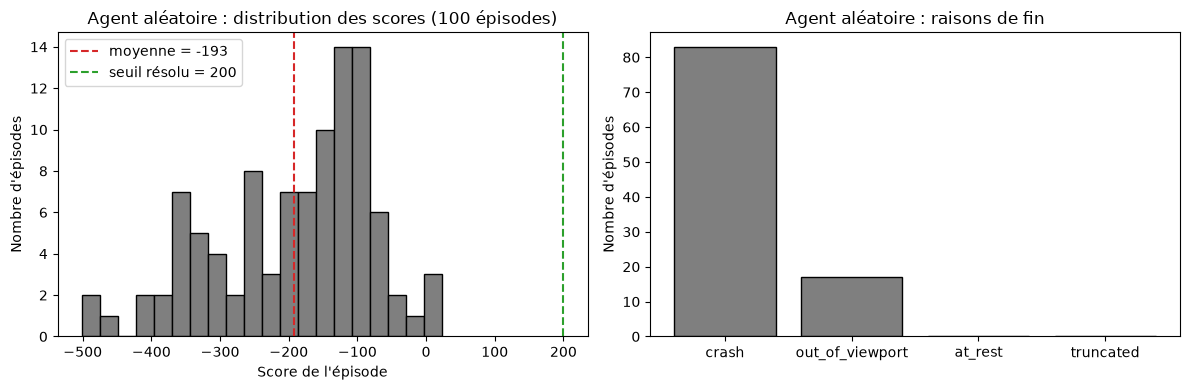

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rewards = [log["reward"] for log in baseline_logs]
axes[0].hist(rewards, bins=20, color="tab:gray", edgecolor="black")
axes[0].axvline(np.mean(rewards), color="tab:red", linestyle="--", label=f"moyenne = {np.mean(rewards):.0f}")
axes[0].axvline(200, color="tab:green", linestyle="--", label="seuil résolu = 200")
axes[0].set_title("Agent aléatoire : distribution des scores (100 épisodes)")
axes[0].set_xlabel("Score de l'épisode")
axes[0].set_ylabel("Nombre d'épisodes")
axes[0].legend()

reasons = baseline_summary["end_reasons"]
axes[1].bar(list(reasons.keys()), list(reasons.values()), color="tab:gray", edgecolor="black")
axes[1].set_title("Agent aléatoire : raisons de fin")
axes[1].set_ylabel("Nombre d'épisodes")

plt.tight_layout()
plt.show()

**Lecture.** L'agent aléatoire se crashe presque toujours en quelques dizaines de steps, avec un score très négatif, et sort parfois du cadre. Il ne se pose jamais. C'est le plancher : la distance entre cette moyenne et 200 est ce que PPO doit apprendre.

## 6. Environnements vectorisés et autoreset

PPO apprend sur des *rollouts* : des lots de transitions collectées avec la politique courante. Faire tourner **plusieurs copies de l'environnement en parallèle** remplit ces lots plus vite et avec des situations plus variées (plusieurs épisodes à des stades différents dans le même lot).

Une copie qui finit son épisode doit repartir automatiquement : c'est l'**autoreset**. Gymnasium (≥ 1.1) propose deux modes :

| Mode | Ce qui se passe quand une copie finit | Conséquence pour PPO |
| --- | --- | --- |
| `NEXT_STEP` (par défaut) | le reset a lieu au step **suivant** : l'action envoyée à ce step est ignorée | une transition fantôme par fin d'épisode, à repérer et exclure du rollout |
| `SAME_STEP` | le reset a lieu **dans le même step** : on reçoit directement l'observation du nouvel épisode, et l'observation finale est dans `info["final_obs"]` | toutes les transitions sont valides ; l'observation finale reste disponible pour les épisodes tronqués |

**Choix : `SAME_STEP`.** Chaque step du rollout est une vraie transition, sans masque à gérer. Et pour un épisode **tronqué**, on dispose de l'observation finale pour estimer la valeur du futur : un épisode coupé par la limite de temps n'est pas réellement fini, la GAE doit en tenir compte.

La cellule ci-dessous le vérifie : au step où une copie finit, l'observation renvoyée est déjà celle du nouvel épisode, l'observation finale est dans `info`, et `get_end_reason` s'applique sans changement.

In [9]:
def make_vec_env(num_envs, seed):
    """Crée num_envs copies de LunarLander en parallèle, avec reset automatique dans le même step."""
    vec_env = gym.make_vec(
        ENV_ID,
        num_envs=num_envs,
        vectorization_mode="sync",
        vector_kwargs={"autoreset_mode": gym.vector.AutoresetMode.SAME_STEP},
    )
    vec_env.action_space.seed(seed)
    return vec_env


vec_env = make_vec_env(num_envs=8, seed=0)
obs, _ = vec_env.reset(seed=0)
print(f"Observations du lot : {obs.shape}  (num_envs, OBS_DIM)")

for step in range(1000):
    obs, rewards, terminated, truncated, info = vec_env.step(vec_env.action_space.sample())
    done = terminated | truncated
    if done.any():
        i = int(np.argmax(done))
        final_obs = info["final_obs"][i]
        reason = get_end_reason(final_obs, rewards[i], terminated[i], truncated[i])
        print(f"Step {step} : la copie {i} a fini ({reason}, reward finale {rewards[i]:.0f})")
        print(f"  x final (info['final_obs'])     = {final_obs[0]:+.3f}")
        print(f"  x renvoyé (déjà le nouvel épisode) = {obs[i][0]:+.3f}")
        break
vec_env.close()

Observations du lot : (8, 8)  (num_envs, OBS_DIM)
Step 65 : la copie 0 a fini (crash, reward finale -100)
  x final (info['final_obs'])     = +0.431
  x renvoyé (déjà le nouvel épisode) = -0.002


## 7. Actor-critic

PPO utilise deux fonctions apprises :

| Élément | Entrée → sortie | Rôle |
| --- | --- | --- |
| **Actor** (politique π) | état → 4 *logits*, transformés en probabilités par softmax | choisit l'action. On **tire** l'action selon ces probabilités pendant l'entraînement (l'exploration est intégrée), on prend la plus probable pendant l'évaluation |
| **Critic** (valeur V) | état → 1 nombre | estime le score que l'agent peut encore espérer depuis cet état avec sa politique actuelle. Il sert de point de comparaison pour juger les actions |

L'**avantage** d'une action, c'est la différence entre ce qu'elle a réellement rapporté et ce que le critic attendait. S'il est positif, l'action a fait mieux que prévu : on la rend plus probable. S'il est négatif, on la rend moins probable.

**Choix : deux réseaux séparés** (et non un tronc commun avec deux têtes). Les deux objectifs n'ont pas la même échelle : la value loss porte sur des scores de l'ordre de la centaine, la policy loss sur des avantages normalisés. Avec un tronc partagé, les gradients du critic peuvent écraser ceux de l'actor, et il faut alors pondérer finement les deux. Séparés, chacun apprend sa propre représentation. Le coût est négligeable ici : deux petits MLP.

**Architecture** : 2 couches cachées de 64 neurones, activation `tanh`, la taille classique pour un état de 8 valeurs. Les poids sont initialisés de façon orthogonale, avec un gain très faible (0.01) sur la sortie de l'actor : au départ, toutes les actions sont presque équiprobables, donc l'agent commence par explorer uniformément.

In [10]:
import copy
from collections import defaultdict

import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical


def layer_init(layer, gain=np.sqrt(2)):
    """Initialisation orthogonale des poids, biais à zéro."""
    nn.init.orthogonal_(layer.weight, gain)
    nn.init.constant_(layer.bias, 0.0)
    return layer


def build_mlp(input_dim, hidden_sizes, output_dim, output_gain):
    """MLP avec activations tanh entre les couches cachées."""
    layers, last_dim = [], input_dim
    for size in hidden_sizes:
        layers += [layer_init(nn.Linear(last_dim, size)), nn.Tanh()]
        last_dim = size
    layers.append(layer_init(nn.Linear(last_dim, output_dim), gain=output_gain))
    return nn.Sequential(*layers)


class ActorCritic(nn.Module):
    """Actor (politique) et critic (valeur) : deux réseaux séparés."""

    def __init__(self, obs_dim, n_actions, hidden_sizes):
        super().__init__()
        self.actor = build_mlp(obs_dim, hidden_sizes, n_actions, output_gain=0.01)
        self.critic = build_mlp(obs_dim, hidden_sizes, 1, output_gain=1.0)

    def get_value(self, obs):
        """V(s) pour un lot d'états."""
        return self.critic(obs).squeeze(-1)

    def get_action_and_value(self, obs, action=None):
        """Tire une action (ou réévalue celle donnée) et renvoie action, log-proba, entropie, valeur."""
        distribution = Categorical(logits=self.actor(obs))
        if action is None:
            action = distribution.sample()
        return action, distribution.log_prob(action), distribution.entropy(), self.get_value(obs)

    def act_greedy(self, obs):
        """Action la plus probable, sans exploration (évaluation)."""
        with torch.no_grad():
            logits = self.actor(torch.as_tensor(obs, dtype=torch.float32))
        return int(torch.argmax(logits).item())

## 8. Rollout storage et GAE

PPO **n'utilise pas de replay buffer**. Il apprend uniquement sur les transitions que sa politique actuelle vient de jouer, puis il les jette : après la mise à jour, elles décrivent le comportement d'une politique qui n'existe plus.

Le rollout storage garde, pour chaque step et chaque environnement : l'état, l'action, sa log-probabilité au moment du tirage, la reward, la fin d'épisode et la valeur estimée par le critic. Après la collecte, on y ajoute les **avantages** et les **retours**.

**GAE (Generalized Advantage Estimation).** Pour chaque step, on calcule l'erreur de prédiction du critic à un pas :

δₜ = rₜ + γ · V(sₜ₊₁) · (1 − doneₜ) − V(sₜ)

L'avantage est ensuite une moyenne pondérée de ces erreurs sur les steps suivants, calculée en remontant le temps :

Aₜ = δₜ + γλ · (1 − doneₜ) · Aₜ₊₁

- **γ** (gamma) : poids du futur dans le score ;
- **λ** (lambda) : compromis biais/variance. λ = 0 ne regarde qu'un pas, et dépend donc beaucoup du critic (biais). λ = 1 additionne toutes les rewards réelles jusqu'à la fin, ce qui est très bruité (variance). 0.95 est le compromis standard ;
- le **retour** cible du critic est Rₜ = Aₜ + V(sₜ).

**Épisodes terminés vs tronqués.** `doneₜ = 1` coupe la chaîne entre deux épisodes : avec l'autoreset `SAME_STEP`, l'état suivant dans le buffer appartient déjà au nouvel épisode. La différence se joue sur la reward :
- **terminé** (crash, sortie du cadre, posé) : il n'y a pas de futur, la cible vaut juste rₜ ;
- **tronqué** (limite de 1000 steps) : le futur existait. On ajoute donc γ · V(observation finale) à la reward de ce step, avec l'observation finale fournie par `info["final_obs"]`. Sinon, on apprendrait au critic que planer jusqu'à la limite de temps ne vaut rien.

In [11]:
class RolloutStorage:
    """Stocke un rollout (n_steps x num_envs transitions) puis calcule avantages et retours."""

    def __init__(self, n_steps, num_envs, obs_dim):
        self.n_steps = n_steps
        self.obs = torch.zeros(n_steps, num_envs, obs_dim)
        self.actions = torch.zeros(n_steps, num_envs, dtype=torch.long)
        self.logprobs = torch.zeros(n_steps, num_envs)
        self.rewards = torch.zeros(n_steps, num_envs)
        self.dones = torch.zeros(n_steps, num_envs)
        self.values = torch.zeros(n_steps, num_envs)
        self.advantages = torch.zeros(n_steps, num_envs)
        self.returns = torch.zeros(n_steps, num_envs)
        self.step = 0

    def add(self, obs, action, logprob, reward, done, value):
        t = self.step
        self.obs[t] = obs
        self.actions[t] = action
        self.logprobs[t] = logprob
        self.rewards[t] = torch.as_tensor(reward, dtype=torch.float32)
        self.dones[t] = torch.as_tensor(done, dtype=torch.float32)
        self.values[t] = value
        self.step += 1

    def compute_gae(self, last_value, gamma, gae_lambda):
        """Avantages GAE et retours, en remontant le temps depuis la fin du rollout."""
        next_advantage = torch.zeros_like(last_value)
        for t in reversed(range(self.n_steps)):
            next_value = last_value if t == self.n_steps - 1 else self.values[t + 1]
            not_done = 1.0 - self.dones[t]
            delta = self.rewards[t] + gamma * next_value * not_done - self.values[t]
            next_advantage = delta + gamma * gae_lambda * not_done * next_advantage
            self.advantages[t] = next_advantage
        self.returns = self.advantages + self.values

    def flatten(self):
        """Tenseurs groupés par élément, aplatis en (n_steps * num_envs, ...), prêts à découper en mini-batches."""
        return {
            "obs": self.obs.reshape(-1, self.obs.shape[-1]),
            "actions": self.actions.reshape(-1),
            "logprobs": self.logprobs.reshape(-1),
            "advantages": self.advantages.reshape(-1),
            "returns": self.returns.reshape(-1),
        }

    def clear(self):
        """Vide le stockage (le rollout est jeté après chaque mise à jour)."""
        self.step = 0

## 9. Loss PPO et mise à jour

On réutilise chaque rollout pendant quelques **époques**, découpé en **mini-batches**. La loss combine trois termes :

**1. Policy loss clippée.** Le *ratio* rₜ = π_nouvelle(aₜ|sₜ) / π_ancienne(aₜ|sₜ) mesure de combien la mise à jour a changé la probabilité de l'action jouée. On maximise :

min( rₜ · Aₜ , clip(rₜ, 1 − ε, 1 + ε) · Aₜ )

Le clip coupe l'intérêt de pousser une action au-delà de ±ε (20 %) par rapport à la politique qui a collecté les données. Une seule mise à jour ne peut donc pas tout casser, et c'est ce qui rend PPO stable. Le `min` garde toujours la version la plus pessimiste.

**2. Value loss.** C'est la MSE entre la prédiction du critic V(sₜ) et le retour Rₜ.

**3. Bonus d'entropie.** L'entropie mesure à quel point la politique est aléatoire. La récompenser empêche l'actor de devenir certain trop tôt, avant d'avoir assez exploré.

loss = policy_loss + c_v · value_loss − c_e · entropie

Deux détails standards :
- les avantages sont **normalisés** par mini-batch (moyenne 0, écart-type 1). L'échelle du pas de gradient ne dépend alors plus de l'échelle des scores ;
- la norme du gradient est **plafonnée** (0.5) pour éviter les mises à jour explosives.

On suit aussi deux indicateurs de santé :
- `approx_kl`, l'écart entre l'ancienne et la nouvelle politique ;
- `clip_frac`, la part des transitions où le clip s'est déclenché.

S'ils s'envolent, les mises à jour sont trop agressives.

In [12]:
def ppo_update(agent, optimizer, storage, config):
    """Plusieurs époques de descente de gradient sur le rollout, par mini-batches."""
    batch = storage.flatten()
    batch_size = batch["obs"].shape[0]
    indices = np.arange(batch_size)
    clip = config["clip_range"]
    stats = defaultdict(list)

    for _ in range(config["n_epochs"]):
        np.random.shuffle(indices)
        for start in range(0, batch_size, config["minibatch_size"]):
            mb = indices[start:start + config["minibatch_size"]]
            _, new_logprob, entropy, new_value = agent.get_action_and_value(batch["obs"][mb], batch["actions"][mb])

            log_ratio = new_logprob - batch["logprobs"][mb]
            ratio = log_ratio.exp()
            advantages = batch["advantages"][mb]
            advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

            # 1. policy loss clippée (on minimise l'opposé de l'objectif)
            policy_loss = -torch.min(ratio * advantages, torch.clamp(ratio, 1 - clip, 1 + clip) * advantages).mean()
            # 2. value loss : MSE entre V(s) et le retour
            value_loss = F.mse_loss(new_value, batch["returns"][mb])
            # 3. bonus d'entropie
            entropy_bonus = entropy.mean()

            loss = policy_loss + config["value_coef"] * value_loss - config["entropy_coef"] * entropy_bonus
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), config["max_grad_norm"])
            optimizer.step()

            with torch.no_grad():
                stats["policy_loss"].append(policy_loss.item())
                stats["value_loss"].append(value_loss.item())
                stats["entropy"].append(entropy_bonus.item())
                stats["approx_kl"].append(((ratio - 1) - log_ratio).mean().item())
                stats["clip_frac"].append(((ratio - 1).abs() > clip).float().mean().item())

    return {key: float(np.mean(values)) for key, values in stats.items()}

## 10. Hyperparamètres

Première configuration, issue des valeurs usuelles de PPO sur des tâches de contrôle de cette taille. Elle sera ajustée un paramètre à la fois pendant la phase de tuning, et chaque changement sera documenté.

| Paramètre | Valeur | Raison |
| --- | --- | --- |
| `total_steps` | 1 000 000 | budget en **steps** plutôt qu'en épisodes : la durée d'un épisode varie de 60 à 1000 steps, alors qu'un step a toujours le même coût. C'est aussi l'unité de comparaison avec DQN |
| `num_envs` | 8 | 8 parties en parallèle : rollouts plus variés et collecte plus rapide |
| `rollout_steps` | 256 | 8 × 256 = 2048 transitions par mise à jour, assez pour couvrir plusieurs épisodes complets |
| `n_epochs` | 10 | chaque rollout est réutilisé 10 fois ; le clip empêche de trop s'en éloigner |
| `minibatch_size` | 64 | 32 mini-batches par époque, soit 320 pas de gradient par rollout |
| `learning_rate` | 3e-4 | valeur standard d'Adam pour PPO |
| `lr_anneal` | False | learning rate constant ; la variante « décroissant » (section 16) le fait descendre linéairement jusqu'à 0 |
| `gamma` | 0.99 | horizon effectif d'environ 100 steps (1 / (1 − γ)) |
| `gae_lambda` | 0.95 | compromis biais/variance standard de la GAE |
| `clip_range` | 0.2 | ratio limité à [0.8, 1.2] |
| `value_coef` | 0.5 | poids de la value loss |
| `entropy_coef` | 0.01 | petite incitation à explorer |
| `max_grad_norm` | 0.5 | plafond de la norme du gradient |
| `hidden_sizes` | (64, 64) | voir section 7 |
| `eval_every` / `eval_episodes` | 10 / 10 | toutes les 10 mises à jour (≈ 20 000 steps), 10 épisodes sans exploration pour suivre les progrès et garder le meilleur modèle |

In [13]:
CONFIG = {
    "total_steps": 1_000_000,
    "num_envs": 8,
    "rollout_steps": 256,
    "n_epochs": 10,
    "minibatch_size": 64,
    "learning_rate": 3e-4,
    "lr_anneal": False,
    "gamma": 0.99,
    "gae_lambda": 0.95,
    "clip_range": 0.2,
    "value_coef": 0.5,
    "entropy_coef": 0.01,
    "max_grad_norm": 0.5,
    "hidden_sizes": (64, 64),
    "eval_every": 10,
    "eval_episodes": 10,
}
batch = CONFIG["num_envs"] * CONFIG["rollout_steps"]
print(f"{batch} transitions par rollout, {CONFIG['total_steps'] // batch} mises à jour au total")

2048 transitions par rollout, 488 mises à jour au total


## 11. Boucle d'entraînement

À chaque itération :
1. **Collecte** : `rollout_steps` steps dans les `num_envs` environnements avec la politique actuelle (actions tirées, donc exploration). Chaque fin d'épisode est loggée au format du contrat.
2. **GAE** : avantages et retours, en estimant la valeur de l'état où le rollout s'arrête.
3. **Mise à jour** PPO, puis le rollout est jeté.
4. **Évaluation périodique** : 10 épisodes sans exploration (action la plus probable), toujours sur les mêmes états de départ (seed fixe) pour que les scores soient comparables d'une évaluation à l'autre. Le meilleur modèle est conservé.

`global_step` compte les transitions **de tous les environnements** : 8 envs × 256 steps = 2048 steps par itération. C'est la même unité que DQN, ce qui rend la comparaison équitable.

In [14]:
def evaluate(agent, env, n_episodes, seed):
    """Score moyen sans exploration sur n_episodes (états de départ fixés par la seed)."""
    logs = run_episodes(env, agent.act_greedy, n_episodes, seed)
    return float(np.mean([log["reward"] for log in logs]))


def train(config, seed, verbose=True):
    """Entraîne un agent PPO et renvoie (agent au meilleur score d'évaluation, logs)."""
    set_seed(seed)
    num_envs, n_steps = config["num_envs"], config["rollout_steps"]
    envs = make_vec_env(num_envs, seed)
    eval_env = make_env()
    agent = ActorCritic(OBS_DIM, N_ACTIONS, config["hidden_sizes"])
    optimizer = torch.optim.Adam(agent.parameters(), lr=config["learning_rate"], eps=1e-5)
    storage = RolloutStorage(n_steps, num_envs, OBS_DIM)

    episode_logs, update_logs, eval_logs = [], [], []
    episode_returns = np.zeros(num_envs)
    episode_lengths = np.zeros(num_envs, dtype=int)
    best_score, best_state = -np.inf, None
    global_step, start = 0, time.time()
    n_updates = config["total_steps"] // (num_envs * n_steps)

    obs, _ = envs.reset(seed=seed)
    obs = torch.as_tensor(obs, dtype=torch.float32)

    for update in range(1, n_updates + 1):
        # 1. Collecte du rollout
        storage.clear()
        for _ in range(n_steps):
            with torch.no_grad():
                action, logprob, _, value = agent.get_action_and_value(obs)
            next_obs, reward, terminated, truncated, info = envs.step(action.numpy())
            global_step += num_envs
            done = terminated | truncated

            # Épisode tronqué : le futur existait, on ajoute sa valeur estimée à la reward
            reward_for_gae = reward.astype(np.float32)
            cut = np.where(truncated & ~terminated)[0]
            if len(cut) > 0:
                final_obs = torch.as_tensor(np.stack(info["final_obs"][cut]), dtype=torch.float32)
                with torch.no_grad():
                    reward_for_gae[cut] += config["gamma"] * agent.get_value(final_obs).numpy()
            storage.add(obs, action, logprob, reward_for_gae, done, value)

            # Logs des épisodes qui viennent de finir (reward réelle, pas celle de la GAE)
            episode_returns += reward
            episode_lengths += 1
            for i in np.where(done)[0]:
                episode_logs.append({
                    "episode": len(episode_logs),
                    "reward": float(episode_returns[i]),
                    "length": int(episode_lengths[i]),
                    "end_reason": get_end_reason(info["final_obs"][i], reward[i], terminated[i], truncated[i]),
                    "global_step": global_step,
                    "wall_time": time.time() - start,
                })
                episode_returns[i], episode_lengths[i] = 0.0, 0
            obs = torch.as_tensor(next_obs, dtype=torch.float32)

        # 2. GAE
        with torch.no_grad():
            last_value = agent.get_value(obs)
        storage.compute_gae(last_value, config["gamma"], config["gae_lambda"])

        # 3. Mise à jour PPO (avec, en option, un learning rate qui décroît linéairement jusqu'à 0)
        if config.get("lr_anneal", False):
            optimizer.param_groups[0]["lr"] = config["learning_rate"] * (1 - (update - 1) / n_updates)
        stats = ppo_update(agent, optimizer, storage, config)
        update_logs.append({"update": update, "global_step": global_step, "wall_time": time.time() - start,
                            "learning_rate": optimizer.param_groups[0]["lr"], **stats})

        # 4. Évaluation périodique et meilleur modèle
        if update % config["eval_every"] == 0 or update == n_updates:
            score = evaluate(agent, eval_env, config["eval_episodes"], seed=10_000 + seed)
            eval_logs.append({"update": update, "global_step": global_step, "wall_time": time.time() - start, "mean_reward": score})
            if score >= best_score:
                best_score, best_state = score, copy.deepcopy(agent.state_dict())
            if verbose:
                recent = [log["reward"] for log in episode_logs[-100:]]
                print(f"step {global_step:>8d} | entraînement (100 derniers) {np.mean(recent):7.1f} | "
                      f"éval {score:7.1f} | meilleure éval {best_score:7.1f} | {time.time() - start:5.0f} s")

    envs.close()
    eval_env.close()
    agent.load_state_dict(best_state)
    logs = {"episodes": episode_logs, "updates": update_logs, "evals": eval_logs, "best_eval": best_score}
    return agent, logs

In [15]:
TRAIN_SEED = SEEDS[0]
train_path = RESULTS_DIR / f"train_seed{TRAIN_SEED}.json"

if TRAIN:
    agent, train_logs = train(CONFIG, seed=TRAIN_SEED)
    with open(train_path, "w") as f:
        json.dump({"meta": {"algo": "ppo", "seed": TRAIN_SEED, "config": CONFIG, "gymnasium": gym.__version__},
                   **train_logs}, f)
    print(f"Logs exportés dans {train_path}")
else:
    with open(train_path) as f:
        train_logs = json.load(f)
    print(f"Logs rechargés depuis {train_path} (TRAIN = False)")

Logs rechargés depuis results/ppo/train_seed0.json (TRAIN = False)


## 12. Courbes d'entraînement

Toutes les courbes sont tracées en fonction de `global_step` (transitions jouées), l'unité commune avec DQN.

Quatre graphiques : le score, la longueur des épisodes, l'entropie de la politique et les raisons de fin. Les losses ne sont pas tracées : en apprentissage par renforcement, les données changent avec la politique, donc la loss ne mesure pas la qualité de l'agent (le score et les raisons de fin, si). Elles restent enregistrées dans les logs (`updates`), avec `approx_kl` et `clip_frac`.

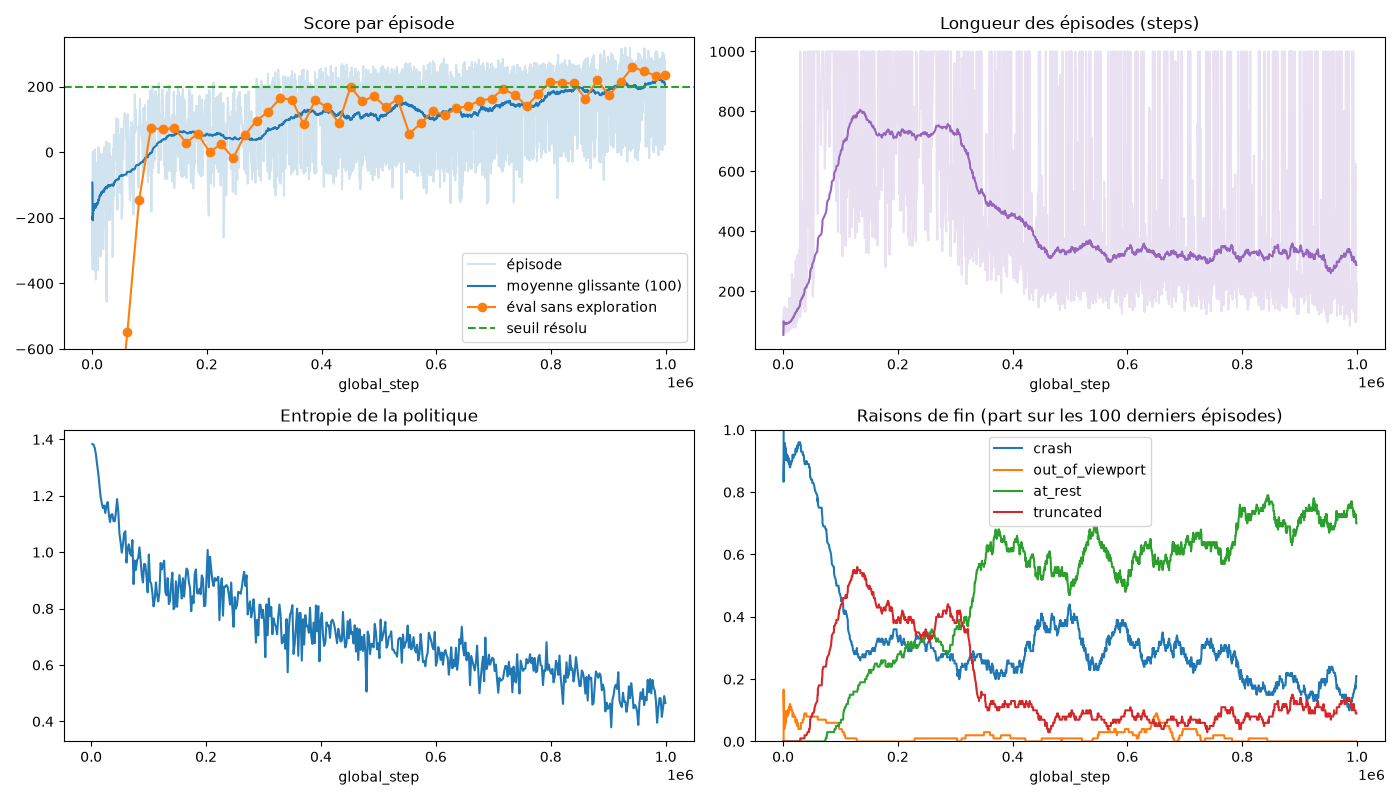

2655 épisodes d'entraînement : {'crash': 874, 'out_of_viewport': 53, 'truncated': 334, 'at_rest': 1394}
Meilleure évaluation pendant l'entraînement (10 épisodes) : 259.2


In [16]:
def moving_average(values, window=100):
    """Moyenne glissante (fenêtre plus courte au début)."""
    values = np.asarray(values, dtype=float)
    cumsum = np.cumsum(np.insert(values, 0, 0.0))
    out = np.empty_like(values)
    for i in range(len(values)):
        lo = max(0, i + 1 - window)
        out[i] = (cumsum[i + 1] - cumsum[lo]) / (i + 1 - lo)
    return out


def plot_training(logs):
    """Score, longueur des épisodes, entropie et raisons de fin, en fonction de global_step."""
    episodes, updates, evals = logs["episodes"], logs["updates"], logs["evals"]
    ep_steps = [e["global_step"] for e in episodes]
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    ax = axes[0, 0]
    rewards = [e["reward"] for e in episodes]
    ax.plot(ep_steps, rewards, alpha=0.2, color="tab:blue", label="épisode")
    ax.plot(ep_steps, moving_average(rewards), color="tab:blue", label="moyenne glissante (100)")
    ax.plot([e["global_step"] for e in evals], [e["mean_reward"] for e in evals], "o-", color="tab:orange", label="éval sans exploration")
    ax.axhline(200, color="tab:green", linestyle="--", label="seuil résolu")
    ax.set_title("Score par épisode")
    ax.set_ylim(-600, 350)
    ax.legend(loc="lower right")

    ax = axes[0, 1]
    lengths = [e["length"] for e in episodes]
    ax.plot(ep_steps, lengths, alpha=0.2, color="tab:purple")
    ax.plot(ep_steps, moving_average(lengths), color="tab:purple")
    ax.set_title("Longueur des épisodes (steps)")

    ax = axes[1, 0]
    ax.plot([u["global_step"] for u in updates], [u["entropy"] for u in updates])
    ax.set_title("Entropie de la politique")

    ax = axes[1, 1]
    window = 100
    for reason in END_REASONS:
        flags = [1.0 if e["end_reason"] == reason else 0.0 for e in episodes]
        ax.plot(ep_steps, moving_average(flags, window), label=reason)
    ax.set_title(f"Raisons de fin (part sur les {window} derniers épisodes)")
    ax.set_ylim(0, 1)
    ax.legend()

    for ax in axes.flat:
        ax.set_xlabel("global_step")
    plt.tight_layout()
    plt.show()


plot_training(train_logs)
counts = Counter(e["end_reason"] for e in train_logs["episodes"])
print(f"{len(train_logs['episodes'])} épisodes d'entraînement : {dict(counts)}")
print(f"Meilleure évaluation pendant l'entraînement (10 épisodes) : {train_logs['best_eval']:.1f}")

**Lecture** (run de référence, seed 0) :

- **Le score** passe de −190 à 206 en 1 million de steps, mais lentement : la moyenne glissante n'atteint 200 qu'à 911 000 steps.
- **Les raisons de fin racontent trois phases** :
    1. au début, presque uniquement des crashs ;
    2. entre 150 000 et 300 000 steps, un **plateau autour de 50**, avec des épisodes d'environ 720 steps et environ 40 % de tronqués : l'agent a appris à ne plus tomber, mais pas encore à se poser, alors il plane jusqu'à la limite ;
    3. à partir d'environ 350 000 steps, les atterrissages deviennent majoritaires.
- **L'entropie** descend de 1.39 (ln 4 : les 4 actions équiprobables) à 0.47 : la politique devient sûre d'elle sans se figer.
- **Les indicateurs de santé restent bas** en fin de run (`approx_kl` ≈ 0.005, `clip_frac` ≈ 6 %) : les mises à jour sont modestes, PPO reste stable.

## 13. Sauvegarde du modèle

Format du contrat : `{"state_dict", "config"}`. La config contient tout ce qu'il faut pour **reconstruire le réseau sans rien deviner** : c'est ce que `model.py` utilisera.

Deux emplacements :
- **`checkpoints/ppo_seed0.pt`** : le modèle de ce run de référence. `checkpoints/` est ignoré par git (modèles intermédiaires, hors rendu) ; sur un clone neuf, il est réentraîné automatiquement.
- **`models/ppo.pt`** : le modèle **rendu**, celui que `model.py` charge à la soutenance. Il est choisi après le tuning, en section 17.

On recharge ensuite le fichier et on rejoue quelques épisodes pour vérifier que la sauvegarde est complète.

In [17]:
MODEL_PATH = MODELS_DIR / "ppo.pt"                              # modèle rendu (section 17)
CHECKPOINTS_DIR = Path("checkpoints")                           # modèles intermédiaires, ignorés par git
CHECKPOINTS_DIR.mkdir(exist_ok=True)
REFERENCE_PATH = CHECKPOINTS_DIR / f"ppo_seed{TRAIN_SEED}.pt"   # run de référence (section 11)


def save_checkpoint(agent, config, path):
    torch.save({
        "state_dict": agent.state_dict(),
        "config": {
            "algo": "ppo",
            "obs_dim": OBS_DIM,
            "n_actions": N_ACTIONS,
            "hidden_sizes": list(config["hidden_sizes"]),
            "shared": False,
            "activation": "tanh",
        },
    }, path)


def load_agent(path):
    checkpoint = torch.load(path, weights_only=False)
    cfg = checkpoint["config"]
    agent = ActorCritic(cfg["obs_dim"], cfg["n_actions"], cfg["hidden_sizes"])
    agent.load_state_dict(checkpoint["state_dict"])
    agent.eval()
    return agent


if TRAIN:
    save_checkpoint(agent, CONFIG, REFERENCE_PATH)
    print(f"Modèle sauvegardé dans {REFERENCE_PATH}")
elif not REFERENCE_PATH.exists():
    # clone neuf : les checkpoints ne sont pas versionnés, on réentraîne la référence (~3 min)
    print(f"{REFERENCE_PATH} absent : réentraînement de la seed {TRAIN_SEED}…")
    agent, _ = train(CONFIG, seed=TRAIN_SEED, verbose=False)
    save_checkpoint(agent, CONFIG, REFERENCE_PATH)

reloaded = load_agent(REFERENCE_PATH)
check_env = make_env()
check_logs = run_episodes(check_env, reloaded.act_greedy, n_episodes=5, seed=123)
check_env.close()
for log in check_logs:
    print(f"épisode {log['episode']} : score {log['reward']:7.1f}  ({log['end_reason']}, {log['length']} steps)")

épisode 0 : score   274.0  (at_rest, 307 steps)
épisode 1 : score     4.4  (crash, 159 steps)
épisode 2 : score   270.4  (at_rest, 193 steps)
épisode 3 : score   286.2  (at_rest, 195 steps)
épisode 4 : score   251.9  (at_rest, 212 steps)


## 14. Évaluation sur 100 épisodes consécutifs

C'est la mesure qui décide si l'environnement est résolu : **moyenne ≥ 200 sur 100 épisodes consécutifs, sans exploration** (l'actor joue toujours son action la plus probable).

On évalue d'abord le **modèle de référence** (seed 0, `checkpoints/ppo_seed0.pt`). Le modèle rendu sera évalué de la même façon en section 17.

Les états de départ sont fixés par `EVAL_SEED = 1000`, différente :
- des seeds d'entraînement (0, 1, 2) ;
- de la seed de l'évaluation périodique (10 000 + seed), qui a servi à **choisir** le meilleur modèle pendant l'entraînement. Réévaluer sur ces mêmes parties avantagerait le modèle retenu.

La dernière ligne estime le risque de la démo de soutenance, où le jury lance **5 épisodes** : on tire 10 000 fois 5 épisodes au hasard parmi les 100 et on compte combien de fois leur moyenne atteint 200.

In [18]:
EVAL_SEED = 1_000
EVAL_EPISODES = 100


def evaluate_100(agent, seed=EVAL_SEED, n_episodes=EVAL_EPISODES):
    """Épisodes consécutifs sans exploration, logs au format du contrat."""
    env = make_env()
    logs = run_episodes(env, agent.act_greedy, n_episodes, seed)
    env.close()
    return logs


def chance_demo(logs, n_demo=5, n_draws=10_000, threshold=200):
    """Part des tirages de n_demo épisodes (parmi ceux évalués) dont la moyenne atteint le seuil."""
    rewards = np.array([log["reward"] for log in logs])
    draws = np.random.default_rng(0).choice(rewards, size=(n_draws, n_demo), replace=True)
    return float((draws.mean(axis=1) >= threshold).mean())


reference_agent = load_agent(REFERENCE_PATH)
eval_logs = evaluate_100(reference_agent)
eval_summary = summarize(eval_logs)
export_results(
    f"eval100_seed{SEEDS[0]}",
    eval_logs,
    meta={"algo": "ppo", "model": str(REFERENCE_PATH), "train_seed": SEEDS[0], "eval_seed": EVAL_SEED,
          "gymnasium": gym.__version__},
)

rewards = np.array([log["reward"] for log in eval_logs])
print(f"Moyenne sur {EVAL_EPISODES} épisodes : {eval_summary['mean']:.1f} ± {eval_summary['std']:.1f}"
      f"  (min {eval_summary['min']:.1f}, max {eval_summary['max']:.1f})")
print(f"Raisons de fin : {eval_summary['end_reasons']}")
print(f"Épisodes ≥ 200 : {(rewards >= 200).sum()} / {EVAL_EPISODES}")
print("Résolu : moyenne ≥ 200" if eval_summary["mean"] >= 200 else "Pas résolu : moyenne < 200")
print(f"Démo de soutenance (5 épisodes) : moyenne ≥ 200 dans {chance_demo(eval_logs):.0%} des tirages")

Moyenne sur 100 épisodes : 212.4 ± 89.2  (min -11.0, max 309.7)
Raisons de fin : {'crash': 15, 'out_of_viewport': 0, 'at_rest': 76, 'truncated': 9}
Épisodes ≥ 200 : 76 / 100
Résolu : moyenne ≥ 200
Démo de soutenance (5 épisodes) : moyenne ≥ 200 dans 67% des tirages


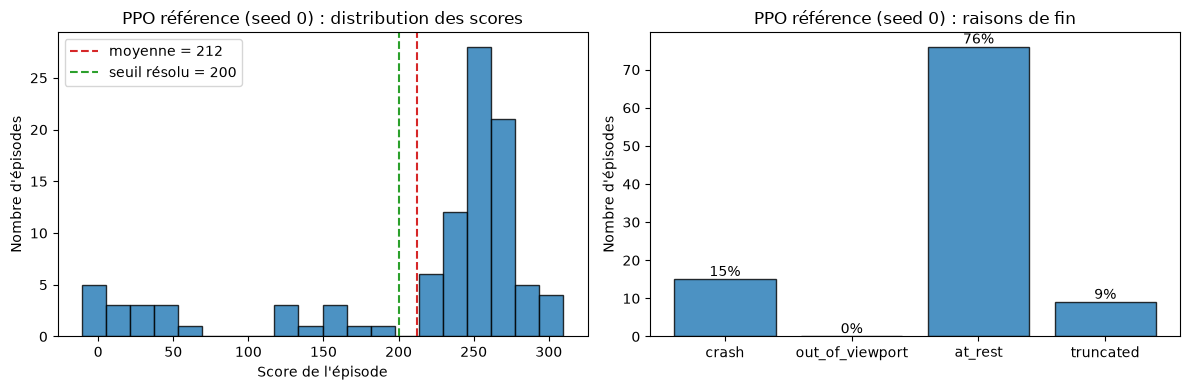

In [19]:
def plot_eval(logs, title):
    """Distribution des scores et raisons de fin d'une évaluation."""
    summary = summarize(logs)
    rewards = [log["reward"] for log in logs]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(rewards, bins=20, color="tab:blue", edgecolor="black", alpha=0.8)
    axes[0].axvline(summary["mean"], color="tab:red", linestyle="--", label=f"moyenne = {summary['mean']:.0f}")
    axes[0].axvline(200, color="tab:green", linestyle="--", label="seuil résolu = 200")
    axes[0].set_title(f"{title} : distribution des scores")
    axes[0].set_xlabel("Score de l'épisode")
    axes[0].set_ylabel("Nombre d'épisodes")
    axes[0].legend()

    reasons = summary["end_reasons"]
    bars = axes[1].bar(list(reasons.keys()), list(reasons.values()), color="tab:blue", edgecolor="black", alpha=0.8)
    axes[1].bar_label(bars, labels=[f"{n / len(logs):.0%}" for n in reasons.values()])
    axes[1].set_title(f"{title} : raisons de fin")
    axes[1].set_ylabel("Nombre d'épisodes")

    plt.tight_layout()
    plt.show()


plot_eval(eval_logs, "PPO référence (seed 0)")

**Lecture.** Le modèle de référence fait **212.4 de moyenne** sur 100 épisodes : l'environnement est résolu, mais de peu.

La distribution est **en deux blocs** :
- 76 épisodes posés, autour de 250 (médiane 253) ;
- 15 épisodes sous 100 points, autant que de crashs, et 9 épisodes tronqués où l'agent plane jusqu'à la limite de 1000 steps.

L'écart-type de 89 vient de ces échecs, pas d'atterrissages plus ou moins bons. Pour la démo à 5 épisodes, la moyenne n'atteint 200 que dans **67 %** des tirages.

L'objectif du tuning est donc clair : **réduire les crashs et les épisodes tronqués**, pas améliorer les atterrissages, qui sont déjà bons.

## 15. Résultats sur plusieurs seeds

Un run isolé ne prouve rien : la courbe d'apprentissage dépend fortement du hasard (poids initiaux, actions tirées, états de départ). On entraîne donc **la même configuration** avec les seeds 0, 1 et 2 du contrat, puis on évalue chaque modèle sur **les mêmes 100 épisodes** (`EVAL_SEED`).

- **Seed 0** : le run de la section 11, dont le modèle est `checkpoints/ppo_seed0.pt`.
- **Seeds 1 et 2** : entraînées ici, environ 3 minutes chacune sur un Mac récent. Leurs modèles vont aussi dans `checkpoints/`. Leurs logs sont exportés dans `results/ppo/`.
- Avec `TRAIN = False`, un run déjà exporté est rechargé au lieu d'être relancé ; un run qui n'existe pas encore est entraîné.

Pour chaque seed, on mesure :
- **steps → 200** : le premier `global_step` où la moyenne des 100 derniers épisodes d'entraînement atteint 200 (avec exploration) ;
- **MA100 finale** : cette moyenne à la fin de l'entraînement ;
- **éval 100** : la moyenne sans exploration sur les 100 épisodes d'évaluation.

In [20]:
def model_path_for(seed):
    """Checkpoint de la configuration de référence pour une seed (seed 0 = run de la section 11)."""
    return REFERENCE_PATH if seed == SEEDS[0] else CHECKPOINTS_DIR / f"ppo_seed{seed}.pt"


def run_seed(seed):
    """Entraîne (ou recharge) le run d'une seed, puis l'évalue sur 100 épisodes."""
    train_file = RESULTS_DIR / f"train_seed{seed}.json"
    model_file = model_path_for(seed)
    must_train = seed != SEEDS[0] and (TRAIN or not train_file.exists() or not model_file.exists())
    if must_train:
        print(f"seed {seed} : entraînement ({CONFIG['total_steps']:,} steps)…")
        seed_agent, logs = train(CONFIG, seed=seed, verbose=False)
        with open(train_file, "w") as f:
            json.dump({"meta": {"algo": "ppo", "seed": seed, "config": CONFIG, "gymnasium": gym.__version__}, **logs}, f)
        save_checkpoint(seed_agent, CONFIG, model_file)
    with open(train_file) as f:
        logs = json.load(f)

    if seed == SEEDS[0]:
        seed_eval = eval_logs                       # déjà calculée en section 14
    else:
        seed_eval = evaluate_100(load_agent(model_file))
        export_results(f"eval100_seed{seed}", seed_eval,
                       meta={"algo": "ppo", "model": str(model_file), "train_seed": seed,
                             "eval_seed": EVAL_SEED, "gymnasium": gym.__version__})
    print(f"seed {seed} : {'entraîné' if must_train else 'rechargé'}, éval 100 = {summarize(seed_eval)['mean']:.1f}")
    return logs, seed_eval


seed_runs = {seed: run_seed(seed) for seed in SEEDS}

seed 0 : rechargé, éval 100 = 212.4
seed 1 : rechargé, éval 100 = 200.6
seed 2 : rechargé, éval 100 = 165.9


In [21]:
def steps_to_threshold(episodes, threshold=200, window=100):
    """Premier global_step où la moyenne glissante sur `window` épisodes atteint le seuil (None sinon)."""
    averages = moving_average([e["reward"] for e in episodes], window)
    for i, (episode, average) in enumerate(zip(episodes, averages)):
        if i + 1 >= window and average >= threshold:
            return episode["global_step"]
    return None


rows = []
for seed, (logs, seed_eval) in seed_runs.items():
    episodes, summary = logs["episodes"], summarize(seed_eval)
    rows.append({
        "seed": seed,
        "steps_to_200": steps_to_threshold(episodes),
        "ma100_final": float(np.mean([e["reward"] for e in episodes[-100:]])),
        "best_periodic_eval": logs["best_eval"],
        "eval100_mean": summary["mean"],
        "eval100_std": summary["std"],
        "at_rest": summary["end_reasons"]["at_rest"] / summary["n_episodes"],
        "crash": summary["end_reasons"]["crash"] / summary["n_episodes"],
        "wall_time": episodes[-1]["wall_time"],
    })

header = f"{'seed':>4} | {'steps → 200':>11} | {'MA100 finale':>12} | {'meilleure éval':>14} | {'éval 100':>15} | {'posés':>5} | {'crashs':>6} | {'temps':>6}"
print(header)
print("-" * len(header))
for r in rows:
    steps = f"{r['steps_to_200']:,}" if r["steps_to_200"] else "jamais"
    print(f"{r['seed']:>4} | {steps:>11} | {r['ma100_final']:>12.1f} | {r['best_periodic_eval']:>14.1f} | "
          f"{r['eval100_mean']:>7.1f} ± {r['eval100_std']:<5.1f} | {r['at_rest']:>5.0%} | {r['crash']:>6.0%} | {r['wall_time']:>5.0f}s")

means = np.array([r["eval100_mean"] for r in rows])
reached = [r["steps_to_200"] for r in rows if r["steps_to_200"]]
print(f"\nÉval 100 épisodes, sur les {len(rows)} seeds : {means.mean():.1f} ± {means.std():.1f}")
print(f"Seeds au-dessus de 200 en éval : {(means >= 200).sum()} / {len(rows)}")
print(f"Seuil de 200 atteint à l'entraînement par {len(reached)} / {len(rows)} seeds"
      + (f", en moyenne à {np.mean(reached):,.0f} steps" if reached else ""))

with open(RESULTS_DIR / "seeds_summary.json", "w") as f:
    json.dump({"config": CONFIG, "eval_seed": EVAL_SEED, "seeds": rows}, f, indent=2)

seed | steps → 200 | MA100 finale | meilleure éval |        éval 100 | posés | crashs |  temps
----------------------------------------------------------------------------------------------
   0 |     911,344 |        205.8 |          259.2 |   212.4 ± 89.2  |   76% |    15% |   170s
   1 |     921,984 |        205.4 |          239.7 |   200.6 ± 92.5  |   78% |    16% |   170s
   2 |     786,920 |        193.9 |          228.3 |   165.9 ± 96.3  |   74% |    18% |   165s

Éval 100 épisodes, sur les 3 seeds : 192.9 ± 19.7
Seeds au-dessus de 200 en éval : 2 / 3
Seuil de 200 atteint à l'entraînement par 3 / 3 seeds, en moyenne à 873,416 steps


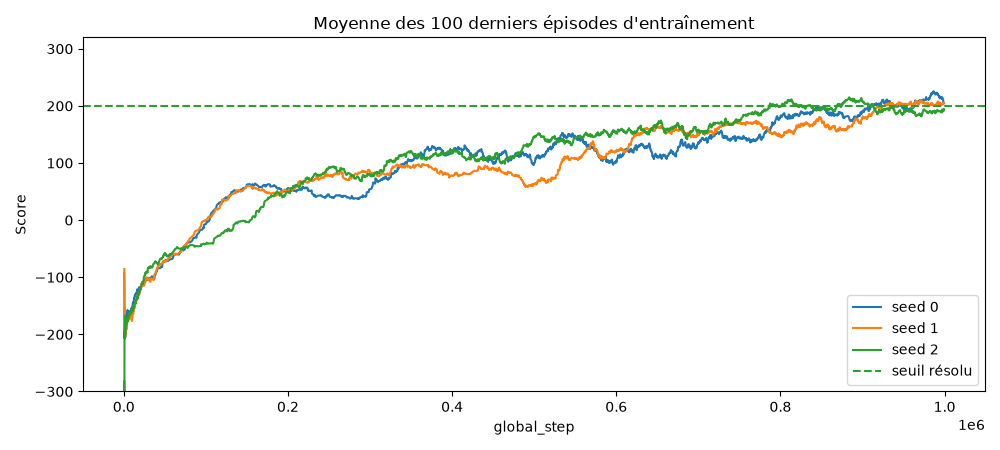

In [22]:
plt.figure(figsize=(10, 4.5))
for seed, (logs, _) in seed_runs.items():
    episodes = logs["episodes"]
    plt.plot([e["global_step"] for e in episodes], moving_average([e["reward"] for e in episodes]),
             label=f"seed {seed}")
plt.axhline(200, color="tab:green", linestyle="--", label="seuil résolu")
plt.title("Moyenne des 100 derniers épisodes d'entraînement")
plt.xlabel("global_step")
plt.ylabel("Score")
plt.ylim(-300, 320)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Lecture.** Les trois seeds racontent la même histoire, ce qui rend le diagnostic solide :

- **Le seuil arrive tard** : la moyenne d'entraînement atteint 200 entre 787 000 et 922 000 steps (873 000 en moyenne), dans les 10 à 20 derniers pourcents du budget. La seed 2 y arrive puis redescend à 194 en fin de run.
- **L'évaluation est juste au seuil** : 212.4, 200.6 et 165.9, soit **192.9 ± 19.7** sur les trois seeds. Seules 2 seeds sur 3 dépassent 200 : la configuration ne résout pas l'environnement de façon fiable.
- **Le même profil d'échec partout** : 74 à 78 % d'atterrissages, 15 à 18 % de crashs, 6 à 9 % d'épisodes tronqués.

La configuration de référence apprend de façon reproductible, mais **pas assez** : c'est un manque d'apprentissage, pas une instabilité. Trois pistes, testées en section 16 :
- l'**horizon** (γ) : avec γ = 0.99, l'agent regarde environ 100 steps devant lui, alors qu'un atterrissage en prend 200 à 300 ;
- la **fin d'entraînement** (learning rate), qui explique la rechute de la seed 2 ;
- la **capacité du réseau**.

## 16. Tuning et expérience comparative

**Méthode** : on change **un seul paramètre à la fois** par rapport à la référence, avec les 3 seeds du contrat et la même évaluation sur 100 épisodes (`EVAL_SEED`). Comme ça, une différence peut être attribuée à ce paramètre et pas au hasard d'un run. La référence n'est pas réentraînée : ce sont les 3 runs de la section 15.

**Prédictions, écrites avant de lancer les runs :**

| Variante | Changement | Prédiction | Pourquoi |
| --- | --- | --- | --- |
| γ 0.999 | `gamma` 0.99 → 0.999 | moins de crashs et de tronqués, éval en hausse | l'horizon passe d'environ 100 à environ 1000 steps : le +100 de l'atterrissage pèse enfin dans les décisions prises en début de descente |
| lr décroissant | `lr_anneal` = True | fin d'entraînement plus stable, écart entre seeds réduit | des corrections de plus en plus petites quand la politique est déjà bonne : moins de rechutes comme celle de la seed 2 |
| réseau 128×128 | `hidden_sizes` (64, 64) → (128, 128) | apprentissage un peu plus rapide | plus de capacité ; pour DQN, Tom a mesuré que 64×64 était trop petit |

**Enregistrement** : chaque run est ajouté à `results/ppo/tuning.json` dès qu'il se termine, au même format que `results/dqn/tuning.json` (variante, seed, éval finale, steps → 200, courbe…). Une interruption ne perd donc rien : une relance reprend où elle s'était arrêtée. Les modèles vont dans `checkpoints/tuning/`, ignoré par git. Compter environ 3 minutes par run, soit environ 30 minutes pour 3 variantes × 3 seeds.

In [23]:
TUNING_PATH = RESULTS_DIR / "tuning.json"
TUNING_DIR = CHECKPOINTS_DIR / "tuning"
TUNING_DIR.mkdir(parents=True, exist_ok=True)

VARIANTS = {
    "référence": {},
    "γ 0.999": {"gamma": 0.999},
    "lr décroissant": {"lr_anneal": True},
    "réseau 128×128": {"hidden_sizes": (128, 128)},
}
FILE_NAMES = {"référence": "reference", "γ 0.999": "gamma-0999", "lr décroissant": "lr-anneal", "réseau 128×128": "net-128"}


def curve_points(episodes, every=5, window=100):
    """Courbe allégée : moyenne glissante sur `window` épisodes, un point tous les `every` épisodes."""
    averages = moving_average([e["reward"] for e in episodes], window)
    return {"global_step": [e["global_step"] for e in episodes[::every]],
            "ma100": [float(a) for a in averages[::every]]}


def tuning_entry(variant, seed, overrides, logs, seed_eval):
    """Une ligne de tuning.json (mêmes champs que results/dqn/tuning.json, + crash et eval_seed)."""
    summary, episodes = summarize(seed_eval), logs["episodes"]
    return {
        "variant": variant,
        "seed": seed,
        "overrides": {key: list(value) if isinstance(value, tuple) else value for key, value in overrides.items()},
        "final_mean": summary["mean"],
        "final_std": summary["std"],
        "at_rest": summary["end_reasons"]["at_rest"] / summary["n_episodes"],
        "crash": summary["end_reasons"]["crash"] / summary["n_episodes"],
        "last100": float(np.mean([e["reward"] for e in episodes[-100:]])),
        "steps_to_200": steps_to_threshold(episodes),
        "best_periodic_eval": logs["best_eval"],
        "wall_time": episodes[-1]["wall_time"],
        "eval_seed": EVAL_SEED,
        "curve": curve_points(episodes),
    }


tuning = json.load(open(TUNING_PATH)) if TUNING_PATH.exists() else []
for variant, overrides in VARIANTS.items():
    for seed in SEEDS:
        if not TRAIN and any(e["variant"] == variant and e["seed"] == seed for e in tuning):
            continue                                    # run déjà fait : rechargé depuis tuning.json
        if variant == "référence":
            logs, seed_eval = seed_runs[seed]           # les runs de la section 15
        else:
            print(f"{variant}, seed {seed} : entraînement…")
            config = {**CONFIG, **overrides}
            seed_agent, logs = train(config, seed=seed, verbose=False)
            save_checkpoint(seed_agent, config, TUNING_DIR / f"{FILE_NAMES[variant]}_seed{seed}.pt")
            seed_eval = evaluate_100(seed_agent)
        tuning = [e for e in tuning if not (e["variant"] == variant and e["seed"] == seed)]
        tuning.append(tuning_entry(variant, seed, overrides, logs, seed_eval))
        with open(TUNING_PATH, "w") as f:
            json.dump(tuning, f)
        print(f"{variant}, seed {seed} : éval 100 = {tuning[-1]['final_mean']:.1f}")

print(f"{len(tuning)} runs dans {TUNING_PATH}")

12 runs dans results/ppo/tuning.json


In [24]:
def variant_stats(variant):
    """Agrège les 3 seeds d'une variante."""
    runs = [e for e in tuning if e["variant"] == variant]
    means = np.array([e["final_mean"] for e in runs])
    reached = [e["steps_to_200"] for e in runs if e["steps_to_200"]]
    return {
        "variant": variant,
        "n": len(runs),
        "eval_mean": float(means.mean()),
        "eval_std": float(means.std()),
        "eval_min": float(means.min()),
        "above_200": int((means >= 200).sum()),
        "at_rest": float(np.mean([e["at_rest"] for e in runs])),
        "crash": float(np.mean([e["crash"] for e in runs])),
        "reached": len(reached),
        "steps_to_200": float(np.mean(reached)) if reached else None,
        "wall_time": float(np.mean([e["wall_time"] for e in runs])),
    }


stats = [variant_stats(v) for v in VARIANTS]
reference = stats[0]
header = (f"{'variante':<16} | {'éval 100 (3 seeds)':>18} | {'Δ réf.':>7} | {'pire seed':>9} | {'≥ 200':>5} | "
          f"{'posés':>5} | {'crashs':>6} | {'steps → 200':>14} | {'temps':>6}")
print(header)
print("-" * len(header))
for s in stats:
    steps = f"{s['steps_to_200']:,.0f} ({s['reached']}/{s['n']})" if s["steps_to_200"] else f"jamais (0/{s['n']})"
    print(f"{s['variant']:<16} | {s['eval_mean']:>9.1f} ± {s['eval_std']:<6.1f} | {s['eval_mean'] - reference['eval_mean']:>+7.1f} | "
          f"{s['eval_min']:>9.1f} | {s['above_200']:>3}/{s['n']} | {s['at_rest']:>5.0%} | {s['crash']:>6.0%} | {steps:>14} | {s['wall_time']:>5.0f}s")

best = max(stats, key=lambda s: (s["above_200"], s["eval_mean"] - s["eval_std"]))
print(f"\nMeilleure variante (seeds ≥ 200, puis moyenne − écart-type) : {best['variant']}")

variante         | éval 100 (3 seeds) |  Δ réf. | pire seed | ≥ 200 | posés | crashs |    steps → 200 |  temps
--------------------------------------------------------------------------------------------------------------
référence        |     192.9 ± 19.7   |    +0.0 |     165.9 |   2/3 |   76% |    16% |  873,416 (3/3) |   169s
γ 0.999          |     267.8 ± 2.8    |   +74.9 |     264.8 |   3/3 |   99% |     0% |  409,184 (3/3) |   169s
lr décroissant   |     236.5 ± 36.4   |   +43.6 |     185.7 |   2/3 |   88% |    10% |  275,684 (2/3) |   172s
réseau 128×128   |     264.5 ± 2.9    |   +71.6 |     261.4 |   3/3 |   92% |     2% |  250,800 (3/3) |   179s

Meilleure variante (seeds ≥ 200, puis moyenne − écart-type) : γ 0.999


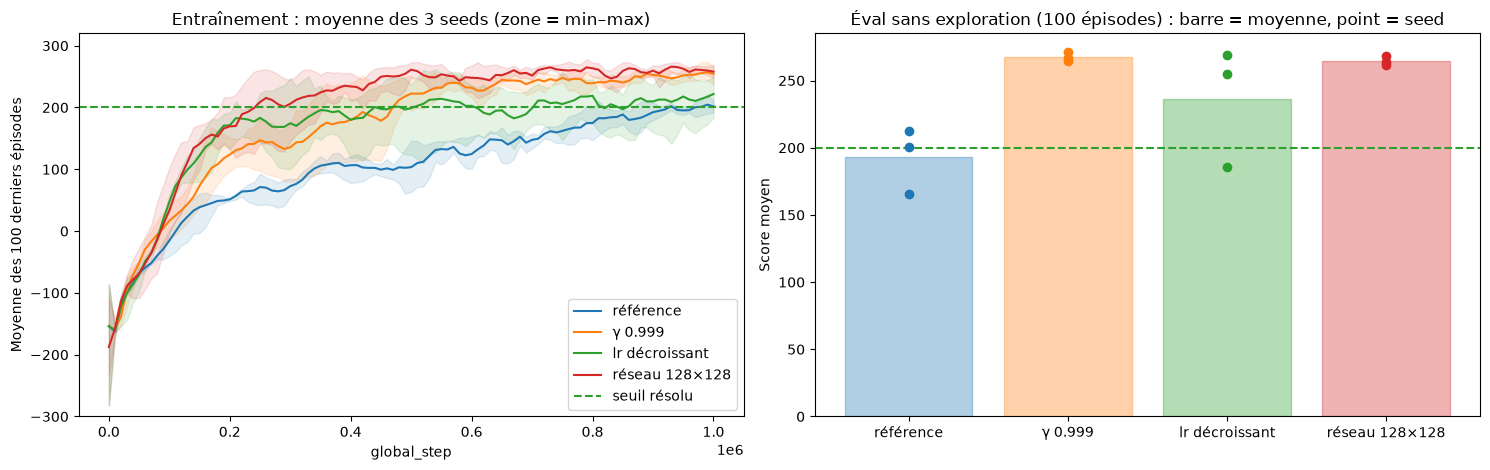

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
grid = np.arange(0, CONFIG["total_steps"] + 1, 10_000)

for k, variant in enumerate(VARIANTS):
    runs = [e for e in tuning if e["variant"] == variant]
    curves = np.array([np.interp(grid, e["curve"]["global_step"], e["curve"]["ma100"]) for e in runs])
    color = f"C{k}"
    axes[0].plot(grid, curves.mean(axis=0), color=color, label=variant)
    axes[0].fill_between(grid, curves.min(axis=0), curves.max(axis=0), color=color, alpha=0.12)

    means = [e["final_mean"] for e in runs]
    axes[1].bar(k, np.mean(means), color=color, alpha=0.35, edgecolor=color)
    axes[1].scatter([k] * len(means), means, color=color, zorder=3)

axes[0].axhline(200, color="tab:green", linestyle="--", label="seuil résolu")
axes[0].set_title("Entraînement : moyenne des 3 seeds (zone = min–max)")
axes[0].set_xlabel("global_step")
axes[0].set_ylabel("Moyenne des 100 derniers épisodes")
axes[0].set_ylim(-300, 320)
axes[0].legend(loc="lower right")

axes[1].axhline(200, color="tab:green", linestyle="--")
axes[1].set_xticks(range(len(VARIANTS)), list(VARIANTS))
axes[1].set_title("Éval sans exploration (100 épisodes) : barre = moyenne, point = seed")
axes[1].set_ylabel("Score moyen")

plt.tight_layout()
plt.show()

**Lecture.** Deux variantes sur trois font beaucoup mieux que la référence, et une des trois prédictions était fausse.

- **γ 0.999 : prédiction confirmée, c'est le meilleur changement.** Éval 267.8 ± 2.8 sur les 3 seeds (+74.9), **99 % d'atterrissages et un seul crash sur 300 épisodes**, et 200 atteint vers 409 000 steps au lieu de 873 000. Les trois seeds sont à moins de 7 points l'une de l'autre (264.8 à 271.5). L'horizon était bien le problème : une récompense reçue 300 steps plus tard pèse 0.99³⁰⁰ ≈ 5 % avec γ = 0.99, contre 0.999³⁰⁰ ≈ 74 % avec γ = 0.999. Le +100 de l'atterrissage devient visible dès le début de la descente.
- **Réseau 128×128 : prédiction confirmée.** 264.5 ± 2.9 (+71.6), et l'apprentissage le plus rapide : 200 vers 251 000 steps. Un peu moins fiable que γ 0.999 : 92 % d'atterrissages, 2 % de crashs, le reste en épisodes tronqués. C'est le même constat que pour DQN : 64 neurones par couche, c'est juste.
- **Learning rate décroissant : prédiction fausse.** Il devait réduire l'écart entre seeds, il l'a augmenté : 236.5 ± 36.4. Deux seeds sont bonnes (254.5 et 269.3), mais la seed 2 reste à 185.7, avec 20 % de crashs, et n'atteint jamais 200. Explication probable : quand le learning rate baisse, une seed qui n'a pas fini d'apprendre ne peut plus rattraper son retard. Il aide une seed déjà bonne, il pénalise une seed en retard.

**Choix : γ 0.999.** C'est la meilleure moyenne, le plus faible écart entre seeds et presque aucun crash, sans coût en temps (169 s par run). La combinaison γ 0.999 + réseau 128×128 n'a pas été testée : c'est la piste suivante.

## 17. Modèle final

**Configuration retenue** : la référence avec **γ = 0.999** (section 16), tout le reste inchangé.

**Seed 0**, par convention, comme pour la référence. On ne prend pas la meilleure des trois seeds sur l'évaluation à 100 épisodes : choisir un modèle sur les épisodes qui servent ensuite à le noter gonflerait le score.

Le run est relancé ici avec la même configuration et la même seed que dans le tuning, pour garder ses logs complets (longueurs, entropie, raisons de fin) et tracer ses courbes. Son meilleur modèle est sauvegardé dans **`models/ppo.pt`** : c'est lui que `model.py` charge à la soutenance. Avec `TRAIN = False`, un run déjà exporté est rechargé.

Entraînement du modèle final (γ = 0.999, seed 0)…
Modèle final sauvegardé dans models/ppo.pt
Seuil de 200 atteint à l'entraînement : 489,896 steps (référence : 911,344 steps)


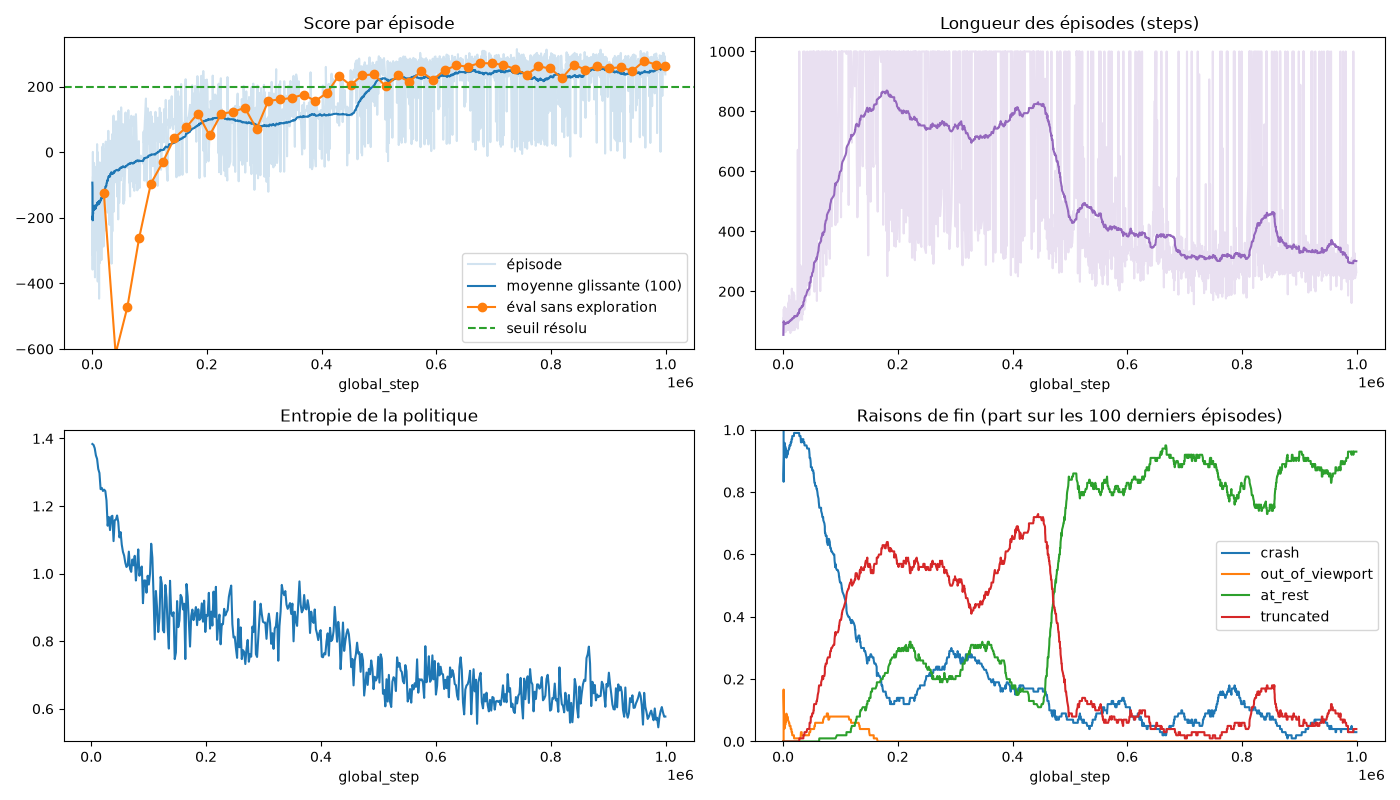

In [26]:
FINAL_CONFIG = {**CONFIG, "gamma": 0.999}
FINAL_SEED = SEEDS[0]
final_train_path = RESULTS_DIR / f"train_final_seed{FINAL_SEED}.json"

if TRAIN or not final_train_path.exists() or not MODEL_PATH.exists():
    print(f"Entraînement du modèle final (γ = {FINAL_CONFIG['gamma']}, seed {FINAL_SEED})…")
    final_agent, final_logs = train(FINAL_CONFIG, seed=FINAL_SEED, verbose=False)
    with open(final_train_path, "w") as f:
        json.dump({"meta": {"algo": "ppo", "seed": FINAL_SEED, "config": FINAL_CONFIG, "gymnasium": gym.__version__},
                   **final_logs}, f)
    save_checkpoint(final_agent, FINAL_CONFIG, MODEL_PATH)
    print(f"Modèle final sauvegardé dans {MODEL_PATH}")
else:
    with open(final_train_path) as f:
        final_logs = json.load(f)
    print(f"Run final rechargé depuis {final_train_path}")

final_agent = load_agent(MODEL_PATH)
fmt_steps = lambda steps: f"{steps:,} steps" if steps else "jamais"
print(f"Seuil de 200 atteint à l'entraînement : {fmt_steps(steps_to_threshold(final_logs['episodes']))} "
      f"(référence : {fmt_steps(steps_to_threshold(train_logs['episodes']))})")
plot_training(final_logs)

                         | référence (γ 0.99) | final (γ 0.999)
éval 100 : moyenne       |              212.4 |           267.1
éval 100 : écart-type    |               89.2 |            28.5
pire épisode             |              -11.0 |            39.2
crash                    |                 15 |               1
out_of_viewport          |                  0 |               0
at_rest                  |                 76 |              99
truncated                |                  9 |               0
épisodes ≥ 200           |                 76 |              99
démo 5 épisodes réussie  |                67% |            100%


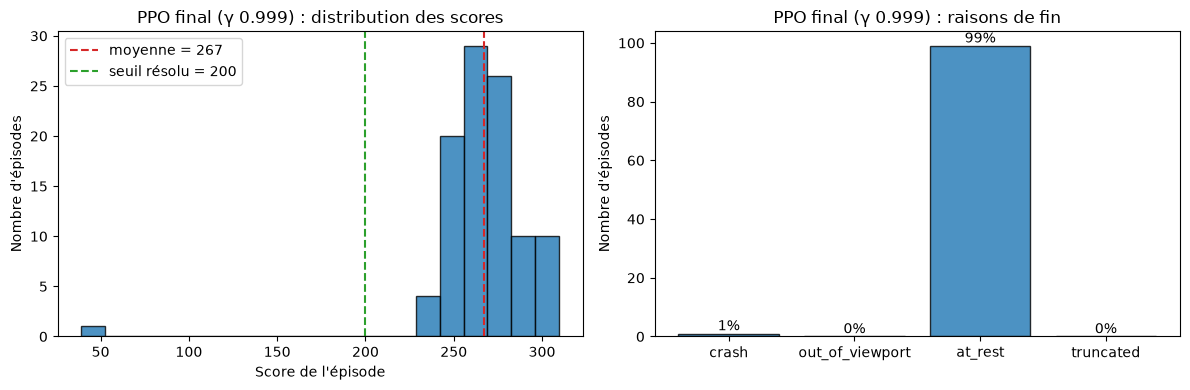

In [27]:
final_eval_logs = evaluate_100(final_agent)
final_summary = summarize(final_eval_logs)
export_results("eval100_final", final_eval_logs,
               meta={"algo": "ppo", "model": str(MODEL_PATH), "config": FINAL_CONFIG, "train_seed": FINAL_SEED,
                     "eval_seed": EVAL_SEED, "gymnasium": gym.__version__})

ref_rewards = np.array([log["reward"] for log in eval_logs])
final_rewards = np.array([log["reward"] for log in final_eval_logs])
print(f"{'':<24} | {'référence (γ 0.99)':>18} | {'final (γ 0.999)':>15}")
print(f"{'éval 100 : moyenne':<24} | {eval_summary['mean']:>18.1f} | {final_summary['mean']:>15.1f}")
print(f"{'éval 100 : écart-type':<24} | {eval_summary['std']:>18.1f} | {final_summary['std']:>15.1f}")
print(f"{'pire épisode':<24} | {eval_summary['min']:>18.1f} | {final_summary['min']:>15.1f}")
for reason in END_REASONS:
    print(f"{reason:<24} | {eval_summary['end_reasons'][reason]:>18} | {final_summary['end_reasons'][reason]:>15}")
print(f"{'épisodes ≥ 200':<24} | {(ref_rewards >= 200).sum():>18} | {(final_rewards >= 200).sum():>15}")
print(f"{'démo 5 épisodes réussie':<24} | {chance_demo(eval_logs):>18.0%} | {chance_demo(final_eval_logs):>15.0%}")

plot_eval(final_eval_logs, "PPO final (γ 0.999)")

**Lecture.** Le modèle final fait **267.1 ± 28.5 sur 100 épisodes consécutifs**, contre 212.4 pour la référence : l'objectif est atteint avec de la marge.

- **Le run est reproductible** : relancé ici, il redonne exactement les chiffres du run γ 0.999 / seed 0 du tuning (267.1 en éval, 200 atteint à 489 896 steps). Sur une même machine, avec la même seed, l'entraînement est déterministe.
- **Les trois phases de la référence sont toujours là, mais plus courtes** :
    1. des crashs jusqu'à environ 100 000 steps ;
    2. un plateau autour de 100 entre 200 000 et 450 000 steps : des épisodes de 750 à 850 steps et jusqu'à 70 % de tronqués, l'agent plane ;
    3. une bascule brutale vers 460 000 steps : la part d'atterrissages passe d'environ 15 % à 85 % en quelques dizaines de milliers de steps.

  La moyenne glissante atteint 200 à **489 896 steps, contre 911 344** pour la référence.
- **Les échecs de la référence ont presque disparu** : 1 crash au lieu de 15, aucun épisode tronqué au lieu de 9, 99 épisodes au-dessus de 200 au lieu de 76. Le pire épisode passe de −11.0 à 39.2, et l'écart-type de 89.2 à 28.5 : il ne reste qu'un seul échec, un crash à 233 steps.
- **Pour la démo à 5 épisodes**, la moyenne dépasse 200 dans 100 % des tirages, contre 67 % avec la référence.

## 18. Comparaison avec DQN

On compare les deux agents sur les quatre critères du sujet. Pour que ce soit équitable :

- **Score final** : les deux modèles rendus (`models/ppo.pt` et `models/dqn.pt`) sont évalués ici **sur les mêmes 100 épisodes** (`EVAL_SEED`), avec la même fonction `run_episodes`.
- **Stabilité** : l'écart entre les 3 seeds communes (0, 1, 2) de la configuration finale de chaque agent, chacune évaluée sur 100 épisodes. Pour PPO, les runs γ 0.999 du tuning (section 16) ; pour DQN, l'export `results/dqn/seeds.json` de `dqn.ipynb` (section 18).
- **Steps pour apprendre** : le premier `global_step` où la moyenne des 100 derniers épisodes d'entraînement atteint 200 (même définition dans les deux notebooks), moyenné sur ces seeds.
- **Temps d'entraînement** : la durée réelle d'un run, et le temps estimé pour atteindre 200. Les deux agents n'ont pas été entraînés sur la même machine (PPO sur le Mac d'Imran, DQN sur celui de Tom) : ces temps donnent un ordre de grandeur, pas une mesure au pourcent près.

Le réseau DQN est reconstruit ici depuis son checkpoint (même architecture que `dqn.ipynb` : MLP ReLU, une Q-value par action), et joue sans exploration : il prend toujours l'action de plus grande Q-value.

In [28]:
DQN_MODEL_PATH = MODELS_DIR / "dqn.pt"
DQN_SEEDS_PATH = Path("results/dqn/seeds.json")   # export de dqn.ipynb (section 20) : config finale sur 3 seeds
PPO_FINAL_VARIANT = "γ 0.999"


class QNetwork(nn.Module):
    """Même architecture que dqn.ipynb : MLP ReLU, une Q-value par action."""

    def __init__(self, obs_dim, n_actions, hidden_sizes):
        super().__init__()
        layers, last_dim = [], obs_dim
        for size in hidden_sizes:
            layers += [nn.Linear(last_dim, size), nn.ReLU()]
            last_dim = size
        layers.append(nn.Linear(last_dim, n_actions))
        self.net = nn.Sequential(*layers)

    def act_greedy(self, obs):
        """Action de plus grande Q-value (aucune exploration)."""
        with torch.no_grad():
            return int(torch.argmax(self.net(torch.as_tensor(obs, dtype=torch.float32))).item())


dqn_checkpoint = torch.load(DQN_MODEL_PATH, map_location="cpu", weights_only=False)
dqn_agent = QNetwork(**dqn_checkpoint["config"]["network"])
dqn_agent.load_state_dict(dqn_checkpoint["state_dict"])
dqn_agent.eval()
dqn_eval_logs = evaluate_100(dqn_agent)
export_results("eval100_dqn_same_episodes", dqn_eval_logs,
               meta={"algo": "dqn", "model": str(DQN_MODEL_PATH), "eval_seed": EVAL_SEED, "gymnasium": gym.__version__})

# Les runs des deux agents sont ramenés au même format : éval 100 épisodes, steps → 200, temps, courbe MA100
with open(DQN_SEEDS_PATH) as f:
    dqn_runs = []
    for r in json.load(f):
        rewards = [h["reward"] for h in r["history"]]
        dqn_runs.append({"seed": r["seed"], "eval_mean": r["eval100"]["mean"], "steps_to_200": r["steps_to_200"],
                         "wall_time": r["wall_time"], "total_steps": r["history"][-1]["global_step"],
                         "curve_steps": [h["global_step"] for h in r["history"]],
                         "curve_ma100": [float(np.mean(rewards[max(0, i - 99):i + 1])) for i in range(len(rewards))]})

ppo_runs = [{"seed": e["seed"], "eval_mean": e["final_mean"], "steps_to_200": e["steps_to_200"],
             "wall_time": e["wall_time"], "total_steps": e["curve"]["global_step"][-1],
             "curve_steps": e["curve"]["global_step"], "curve_ma100": e["curve"]["ma100"]}
            for e in tuning if e["variant"] == PPO_FINAL_VARIANT]


def runs_stats(runs):
    """Stabilité, vitesse et coût de la configuration finale d'un agent, sur ses 3 seeds."""
    means = np.array([r["eval_mean"] for r in runs])
    reached = [r["steps_to_200"] for r in runs if r["steps_to_200"]]
    total_steps = int(round(np.mean([r["total_steps"] for r in runs]), -4))   # budget arrondi (1 000 000 / 300 000)
    wall = float(np.mean([r["wall_time"] for r in runs]))
    return {"n_seeds": len(runs), "seed_means": means.round(1).tolist(), "seed_mean": float(means.mean()),
            "seed_std": float(means.std()), "steps_to_200": float(np.mean(reached)) if reached else None,
            "reached": len(reached), "total_steps": total_steps, "wall_time": wall,
            "ms_per_1000_steps": 1e6 * wall / total_steps}


comparison = {
    "PPO": {**runs_stats(ppo_runs), "eval": summarize(final_eval_logs), "logs": final_eval_logs},
    "DQN": {**runs_stats(dqn_runs), "eval": summarize(dqn_eval_logs), "logs": dqn_eval_logs},
}


def row(label, fmt):
    print(f"{label:<38} | " + " | ".join(f"{fmt(comparison[a]):>16}" for a in ("PPO", "DQN")))


print(f"{'':<38} | {'PPO':>16} | {'DQN':>16}")
print("-" * 76)
row("Score final (mêmes 100 épisodes)", lambda c: f"{c['eval']['mean']:.1f} ± {c['eval']['std']:.1f}")
row("  atterrissages / crashs", lambda c: f"{c['eval']['end_reasons']['at_rest']} / {c['eval']['end_reasons']['crash']}")
row("  pire épisode", lambda c: f"{c['eval']['min']:.1f}")
row("  démo 5 épisodes réussie", lambda c: f"{chance_demo(c['logs']):.0%}")
row("Stabilité : éval entre seeds", lambda c: f"{c['seed_mean']:.1f} ± {c['seed_std']:.1f} ({c['n_seeds']})")
row("Steps pour atteindre 200", lambda c: f"{c['steps_to_200']:,.0f} ({c['reached']}/{c['n_seeds']})" if c["steps_to_200"] else "jamais")
row("Budget d'entraînement (steps)", lambda c: f"{c['total_steps']:,}")
row("Temps d'un run", lambda c: f"{c['wall_time']:.0f} s")
row("Temps pour 1000 steps", lambda c: f"{c['ms_per_1000_steps']:.0f} ms")
row("Temps estimé pour atteindre 200", lambda c: f"{c['steps_to_200'] * c['ms_per_1000_steps'] / 1e6:.0f} s" if c["steps_to_200"] else "—")

with open(RESULTS_DIR / "comparison_dqn.json", "w") as f:
    json.dump({a: {k: v for k, v in c.items() if k != "logs"} for a, c in comparison.items()}, f, indent=2)

                                       |              PPO |              DQN
----------------------------------------------------------------------------
Score final (mêmes 100 épisodes)       |     267.1 ± 28.5 |     274.4 ± 17.8
  atterrissages / crashs               |           99 / 1 |          100 / 0
  pire épisode                         |             39.2 |            216.2
  démo 5 épisodes réussie              |             100% |             100%
Stabilité : éval entre seeds           |  267.8 ± 2.8 (3) | 253.9 ± 12.7 (3)
Steps pour atteindre 200               |    409,184 (3/3) |    231,590 (3/3)
Budget d'entraînement (steps)          |        1,000,000 |          300,000
Temps d'un run                         |            169 s |            237 s
Temps pour 1000 steps                  |           169 ms |           790 ms
Temps estimé pour atteindre 200        |             69 s |            183 s


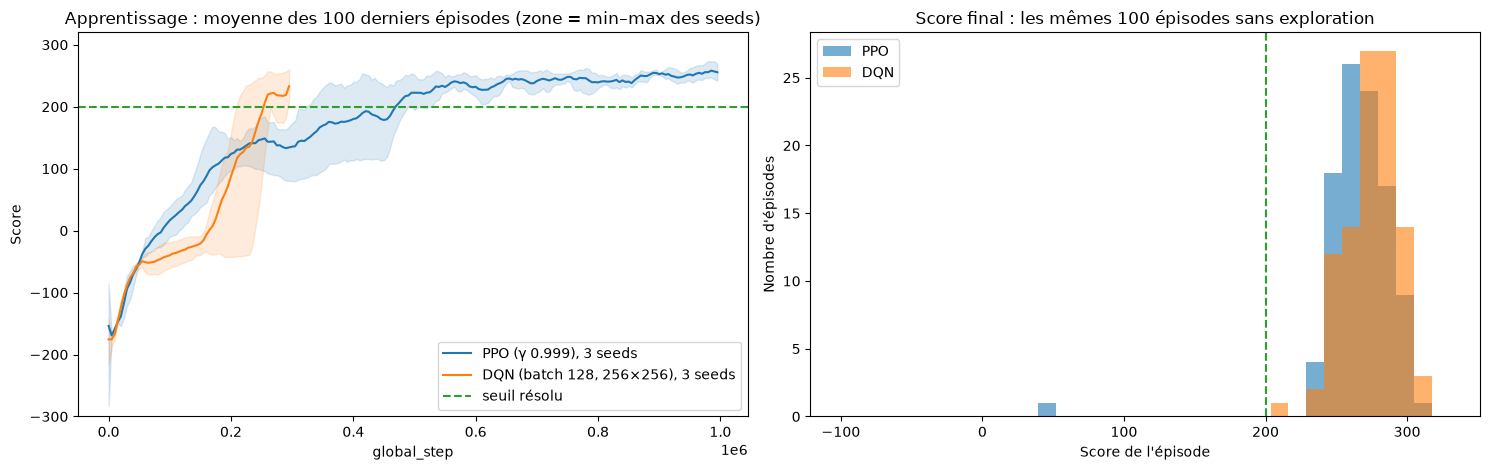

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

for agent_name, runs, color in [("PPO (γ 0.999)", ppo_runs, "tab:blue"),
                                ("DQN (batch 128, 256×256)", dqn_runs, "tab:orange")]:
    end = min(r["curve_steps"][-1] for r in runs)
    grid = np.arange(0, end + 1, 5_000)
    curves = np.array([np.interp(grid, r["curve_steps"], r["curve_ma100"]) for r in runs])
    axes[0].plot(grid, curves.mean(axis=0), color=color, label=f"{agent_name}, {len(runs)} seeds")
    axes[0].fill_between(grid, curves.min(axis=0), curves.max(axis=0), color=color, alpha=0.15)
axes[0].axhline(200, color="tab:green", linestyle="--", label="seuil résolu")
axes[0].set_title("Apprentissage : moyenne des 100 derniers épisodes (zone = min–max des seeds)")
axes[0].set_xlabel("global_step")
axes[0].set_ylabel("Score")
axes[0].set_ylim(-300, 320)
axes[0].legend(loc="lower right")

all_scores = [log["reward"] for log in final_eval_logs + dqn_eval_logs]
bins = np.linspace(min(-100, min(all_scores)), max(330, max(all_scores)), 35)
axes[1].hist([log["reward"] for log in final_eval_logs], bins=bins, alpha=0.6, color="tab:blue", label="PPO")
axes[1].hist([log["reward"] for log in dqn_eval_logs], bins=bins, alpha=0.6, color="tab:orange", label="DQN")
axes[1].axvline(200, color="tab:green", linestyle="--")
axes[1].set_title("Score final : les mêmes 100 épisodes sans exploration")
axes[1].set_xlabel("Score de l'épisode")
axes[1].set_ylabel("Nombre d'épisodes")
axes[1].legend()

plt.tight_layout()
plt.show()

**Lecture.** Les deux agents atteignent l'objectif, et aucun ne gagne sur les quatre critères :

| Critère | Meilleur | Chiffres |
| --- | --- | --- |
| Score final | DQN, de peu | 274.4 ± 17.8 contre 267.1 ± 28.5 sur les mêmes 100 épisodes |
| Stabilité entre seeds | PPO | 267.8 ± 2.8 (264.8 à 271.5) contre 253.9 ± 12.7 (236.2 à 265.6) |
| Steps pour atteindre 200 | DQN | 231 590 contre 409 184 : 1.8 fois moins |
| Temps | PPO | 169 ms contre 790 ms pour 1 000 steps ; 69 s contre 183 s pour atteindre 200 |

- **Score final** : 7 points d'écart, c'est peu face à la dispersion des épisodes (écarts-types de 18 et 28). La vraie différence est dans le pire épisode : 216.2 pour DQN, 39.2 pour PPO (son seul crash). Pour la démo à 5 épisodes, les deux réussissent dans 100 % des tirages.
- **DQN apprend en moins de steps parce qu'il est *off-policy*.** Chaque transition reste dans le replay buffer (100 000 places), où elle est tirée environ 32 fois en moyenne (un batch de 128 tous les 4 steps). PPO est *on-policy* : il réutilise chaque rollout pendant 10 epochs, puis le jette, car ces données ne correspondent plus à la nouvelle politique.
- **PPO est plus rapide en temps réel parce qu'un step lui coûte moins cher.** DQN fait une mise à jour d'un réseau 256×256 tous les 4 steps (batch de 128, plus le target network). PPO choisit les actions des 8 environnements vectorisés en une seule passe d'un petit réseau 64×64, puis fait ses mises à jour d'un bloc tous les 2 048 steps. Un step lui coûte environ 4.7 fois moins cher, ce qui compense largement ses 1.8 fois plus de steps.
- **PPO est plus stable d'une seed à l'autre.** Sur les courbes, la zone min–max de DQN est large pendant tout le décollage (150 000 à 270 000 steps selon la seed), celle de PPO se resserre une fois le seuil passé. Explication probable : la loss clippée limite la taille de chaque mise à jour de la politique, alors que DQN dépend de ce que l'exploration a mis dans le buffer.
- **Les limites de cette comparaison** :
    - les temps viennent de deux machines (PPO sur celle d'Imran, DQN sur celle de Tom) : ce sont des ordres de grandeur ;
    - les budgets d'entraînement diffèrent (1 000 000 steps contre 300 000) ;
    - chaque agent a été tuné de son côté.
- **Le choix des 100 épisodes compte** : le même `dqn.pt` fait 265.6 dans `dqn.ipynb` et 274.4 ici, uniquement parce que ce ne sont pas les mêmes épisodes. C'est pour ça que les deux modèles sont évalués ici sur les mêmes.

## 19. Conclusion

**Résultat.** L'agent PPO rendu (`models/ppo.pt`) fait **267.1 ± 28.5 sur 100 épisodes consécutifs**, sans exploration, avec 99 % d'atterrissages. Le résultat ne vient pas d'une seed chanceuse : la même configuration fait **267.8 ± 2.8 sur 3 seeds**, toutes au-dessus de 260.

**Ce qui a fait la différence**

- **L'horizon, avec γ = 0.999.** C'est le changement décisif. Un atterrissage dure environ 285 steps (longueur moyenne en éval). Avec γ = 0.99, le +100 de la fin ne pèse plus que ~6 % au début de la descente ; avec γ = 0.999, il en pèse ~75 %. Ce seul changement supprime presque tous les crashs et les vols stationnaires, et divise par deux le nombre de steps pour atteindre 200.
- **Les épisodes tronqués traités comme tels.** La limite de 1 000 steps n'est pas une vraie fin : on ajoute γ·V(`final_obs`) à la dernière reward. Sinon, le critic apprendrait qu'un état en plein vol ne vaut rien, simplement parce que le temps est écoulé.
- **L'autoreset en mode SAME_STEP.** Avec le mode par défaut (NEXT_STEP), chaque fin d'épisode crée une transition fantôme entre l'état final et l'état initial suivant.
- **La méthode.** Une seule variable changée à la fois, 3 seeds, une prédiction écrite avant chaque run, et les mêmes 100 épisodes pour toutes les évaluations.

**Ce qui n'a pas marché, et pourquoi**

- **La configuration de départ ne suffisait pas** : 192.9 ± 19.7 sur 3 seeds, une seed sur trois sous 200 (165.9), et le seuil atteint seulement dans les 10 à 20 derniers pourcents du budget. Le diagnostic de la section 15 : un manque d'apprentissage, reproductible d'une seed à l'autre, pas une instabilité.
- **Le learning rate décroissant : notre prédiction était fausse** (section 16). Il devait réduire l'écart entre seeds ; il l'a creusé (236.5 ± 36.4). Une seed en retard n'a plus le temps de rattraper son retard quand le pas d'apprentissage diminue.
- **Une même seed ne donne pas le même résultat sur deux machines.** Sur le Mac d'Imran, la référence atteint 200 à 911 000 steps ; sur une machine Linux, avec la même seed, à 229 000. Les petites différences de calcul en virgule flottante s'amplifient au fil de l'entraînement. C'est pour ça que toutes les conclusions reposent sur 3 seeds, et que tous les chiffres de ce notebook viennent de la même machine.
- **La fenêtre pygame faisait planter le kernel du notebook.** On visualise donc un atterrissage avec une animation `rgb_array` (dossier `soutenance/`). La fenêtre d'affichage est réservée à `model.py`.
- **Il a fallu aligner les deux notebooks** sur la détection de la raison de fin, le format des logs et la définition de « steps pour atteindre 200 ». Sans ça, la comparaison de la section 18 ne tiendrait pas.

**Limites**

- La combinaison γ 0.999 + réseau 128×128 n'a pas été testée.
- 3 seeds suffisent pour voir les grands écarts (+75 points), pas pour départager γ 0.999 et le réseau 128×128 (267.8 contre 264.5).
- Le modèle rendu garde un échec sur 100 épisodes (un crash à 39.2), alors que DQN n'en a aucun sur les mêmes épisodes.

**Pistes**

- Tester γ 0.999 avec le réseau 128×128.
- Réduire le budget d'entraînement : le seuil est atteint vers 410 000 steps, et la fin du run n'apporte plus que quelques points.
- Mesurer les temps des deux agents sur la même machine.